In [ ]:
!pip install sentence-transformers pillow

In [ ]:
from sentence_transformers import SentenceTransformer, util
from PIL import Image

# Cargar modelo (se descarga la primera vez)
model = SentenceTransformer('clip-ViT-B-32')

# Cargar imágenes
img1 = Image.open("image1.jpg")
img2 = Image.open("image2.jpg")

# Generar embeddings
emb1 = model.encode(img1)
emb2 = model.encode(img2)

# Similitud coseno
similitud = util.cos_sim(emb1, emb2).item()
porcentaje = round(((similitud + 1) / 2) * 100, 2)

print(f"Similitud: {porcentaje}%")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Similitud: 94.69%


In [ ]:
!pip install scikit-image opencv-python matplotlib

Similitud estructural: 50.12%


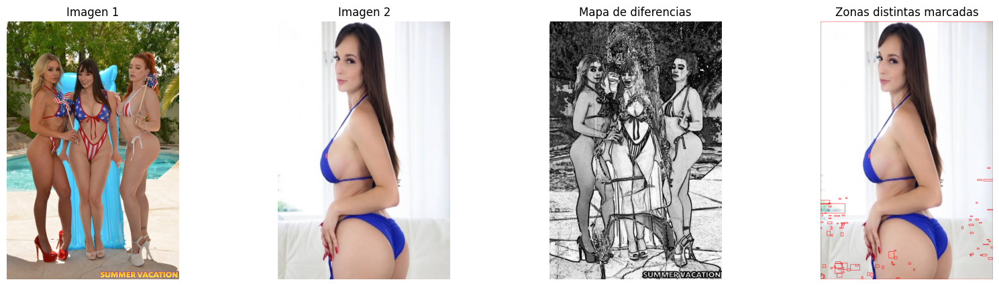

In [ ]:
import cv2
import numpy as np
from skimage.metrics import structural_similarity as ssim
import matplotlib.pyplot as plt

# Cargar imágenes (deben tener el mismo tamaño)
img1 = cv2.imread("image1.jpg")
img2 = cv2.imread("image4.jpg")

# Redimensionar img2 al tamaño de img1 si no coinciden
if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# Convertir a escala de grises
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# SSIM con mapa de diferencias
score, diff = ssim(gray1, gray2, full=True)
diff = (diff * 255).astype("uint8")

print(f"Similitud estructural: {score*100:.2f}%")

# Umbralizar para resaltar zonas distintas
thresh = cv2.threshold(diff, 200, 255, cv2.THRESH_BINARY_INV)[1]
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Dibujar rectángulos donde hay diferencias
img_marcada = img2.copy()
for c in contours:
    if cv2.contourArea(c) > 40:  # ignora ruido/diferencias mínimas
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(img_marcada, (x, y), (x+w, y+h), (0, 0, 255), 2)

# Mostrar resultados
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)); axs[0].set_title("Imagen 1")
axs[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)); axs[1].set_title("Imagen 2")
axs[2].imshow(diff, cmap='gray'); axs[2].set_title("Mapa de diferencias")
axs[3].imshow(cv2.cvtColor(img_marcada, cv2.COLOR_BGR2RGB)); axs[3].set_title("Zonas distintas marcadas")
for ax in axs: ax.axis('off')
plt.show()

In [ ]:
!pip install scikit-image opencv-python matplotlib numpy scipy

Alineación: 28 matches usados, 10.7% inliers
REPORTE DE COMPARACIÓN
Calidad de alineación: 10.7% inliers
SSIM (gris):        49.65%
SSIM (color):        45.06%
Similitud histograma: -16.05%
Área distinta total:  95.42%
Regiones detectadas:  66
--------------------------------------------------
  Región 1: pos=(0,0) tamaño=1440x2158 → 94.765% de la imagen
  Región 2: pos=(1224,1640) tamaño=58x76 → 0.063% de la imagen
  Región 3: pos=(1226,1758) tamaño=88x45 → 0.053% de la imagen
  Región 4: pos=(1292,1943) tamaño=99x45 → 0.051% de la imagen
  Región 5: pos=(1378,1808) tamaño=62x44 → 0.041% de la imagen
  Región 6: pos=(1229,1622) tamaño=100x21 → 0.041% de la imagen
  Región 7: pos=(1387,1596) tamaño=53x47 → 0.039% de la imagen
  Región 8: pos=(1241,1936) tamaño=41x32 → 0.029% de la imagen
  Región 9: pos=(1381,1707) tamaño=59x19 → 0.022% de la imagen
  Región 10: pos=(1332,1630) tamaño=45x24 → 0.02% de la imagen


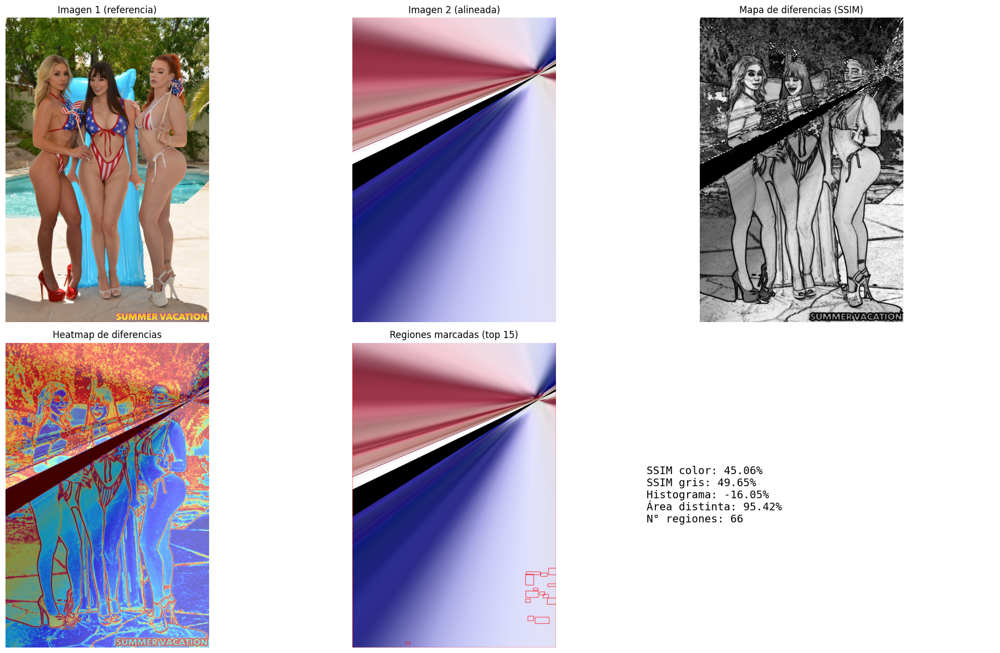

In [ ]:
import cv2
import numpy as np
from skimage.metrics import structural_similarity as ssim
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy import ndimage


class ImageComparator:
    def __init__(self, path1, path2, align=True, verbose=True):
        self.verbose = verbose
        self.img1_orig = cv2.imread(path1)
        self.img2_orig = cv2.imread(path2)

        if self.img1_orig is None or self.img2_orig is None:
            raise FileNotFoundError("No se pudo cargar una de las imágenes, revisa la ruta.")

        self.img1 = self.img1_orig.copy()
        self.img2 = self.img2_orig.copy()

        # Igualar tamaño
        if self.img1.shape[:2] != self.img2.shape[:2]:
            self.img2 = cv2.resize(self.img2, (self.img1.shape[1], self.img1.shape[0]))

        # Alineación por features (ORB + homografía) para corregir rotación/traslación/escala
        self.align_score = None
        if align:
            self.img2, self.align_score = self._align_images(self.img1, self.img2)

        self.gray1 = cv2.cvtColor(self.img1, cv2.COLOR_BGR2GRAY)
        self.gray2 = cv2.cvtColor(self.img2, cv2.COLOR_BGR2GRAY)

        self.results = {}

    # ---------- ALINEACIÓN ----------
    def _align_images(self, ref, target, max_features=2000, good_match_pct=0.15):
        orb = cv2.ORB_create(max_features)
        gray_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
        gray_target = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)

        kp1, des1 = orb.detectAndCompute(gray_ref, None)
        kp2, des2 = orb.detectAndCompute(gray_target, None)

        if des1 is None or des2 is None or len(kp1) < 10 or len(kp2) < 10:
            if self.verbose:
                print("No hay suficientes features para alinear, se usa la imagen sin alinear.")
            return target, None

        matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
        matches = matcher.match(des1, des2)
        matches = sorted(matches, key=lambda x: x.distance)

        n_good = max(int(len(matches) * good_match_pct), 10)
        matches = matches[:n_good]

        if len(matches) < 4:
            return target, None

        pts1 = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
        pts2 = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

        H, mask = cv2.findHomography(pts2, pts1, cv2.RANSAC, 5.0)
        if H is None:
            return target, None

        h, w = ref.shape[:2]
        aligned = cv2.warpPerspective(target, H, (w, h))

        inliers_pct = (mask.sum() / len(mask)) * 100 if mask is not None else None
        if self.verbose:
            print(f"Alineación: {len(matches)} matches usados, {inliers_pct:.1f}% inliers")

        return aligned, inliers_pct

    # ---------- SSIM MULTICANAL ----------
    def compute_ssim(self):
        # SSIM por canal de color (más sensible a cambios de color que solo escala de grises)
        score_gray, diff_gray = ssim(self.gray1, self.gray2, full=True)

        scores_color = []
        diffs_color = []
        for ch in range(3):
            s, d = ssim(self.img1[:, :, ch], self.img2[:, :, ch], full=True)
            scores_color.append(s)
            diffs_color.append(d)

        diff_color = np.mean(diffs_color, axis=0)
        score_color = np.mean(scores_color)

        self.results['ssim_gray'] = score_gray
        self.results['ssim_color'] = score_color
        self.diff_map = (diff_color * 255).astype("uint8")
        return score_gray, score_color

    # ---------- HISTOGRAMA DE COLOR ----------
    def compute_histogram_similarity(self):
        hist_sim = []
        for ch in range(3):
            h1 = cv2.calcHist([self.img1], [ch], None, [256], [0, 256])
            h2 = cv2.calcHist([self.img2], [ch], None, [256], [0, 256])
            cv2.normalize(h1, h1)
            cv2.normalize(h2, h2)
            corr = cv2.compareHist(h1, h2, cv2.HISTCMP_CORREL)
            hist_sim.append(corr)
        self.results['histogram_similarity'] = np.mean(hist_sim)
        return self.results['histogram_similarity']

    # ---------- DETECCIÓN DE REGIONES DIFERENTES ----------
    def detect_diff_regions(self, thresh_val=200, min_area=60, dilate_iter=2):
        thresh = cv2.threshold(self.diff_map, thresh_val, 255, cv2.THRESH_BINARY_INV)[1]

        # Dilatar para fusionar regiones cercanas fragmentadas
        kernel = np.ones((5, 5), np.uint8)
        thresh = cv2.dilate(thresh, kernel, iterations=dilate_iter)

        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        boxes = []
        total_diff_area = 0
        img_area = self.img1.shape[0] * self.img1.shape[1]

        for c in contours:
            area = cv2.contourArea(c)
            if area > min_area:
                x, y, w, h = cv2.boundingRect(c)
                boxes.append({'x': x, 'y': y, 'w': w, 'h': h, 'area': area,
                               'pct_imagen': round(area / img_area * 100, 3)})
                total_diff_area += area

        boxes = sorted(boxes, key=lambda b: b['area'], reverse=True)
        self.results['n_regiones'] = len(boxes)
        self.results['pct_area_diferente'] = round(total_diff_area / img_area * 100, 2)
        self.diff_boxes = boxes
        return boxes

    # ---------- HEATMAP OVERLAY ----------
    def make_heatmap_overlay(self, alpha=0.5):
        heatmap = cv2.applyColorMap(255 - self.diff_map, cv2.COLORMAP_JET)
        overlay = cv2.addWeighted(self.img2, 1 - alpha, heatmap, alpha, 0)
        return overlay

    # ---------- REPORTE ----------
    def report(self):
        print("=" * 50)
        print("REPORTE DE COMPARACIÓN")
        print("=" * 50)
        if self.align_score is not None:
            print(f"Calidad de alineación: {self.align_score:.1f}% inliers")
        print(f"SSIM (gris):        {self.results['ssim_gray']*100:.2f}%")
        print(f"SSIM (color):        {self.results['ssim_color']*100:.2f}%")
        print(f"Similitud histograma: {self.results['histogram_similarity']*100:.2f}%")
        print(f"Área distinta total:  {self.results['pct_area_diferente']}%")
        print(f"Regiones detectadas:  {self.results['n_regiones']}")
        print("-" * 50)
        for i, b in enumerate(self.diff_boxes[:10], 1):
            print(f"  Región {i}: pos=({b['x']},{b['y']}) tamaño={b['w']}x{b['h']} "
                  f"→ {b['pct_imagen']}% de la imagen")
        print("=" * 50)

    # ---------- VISUALIZACIÓN ----------
    def plot(self, max_boxes=15):
        img_marcada = self.img2.copy()
        for b in self.diff_boxes[:max_boxes]:
            cv2.rectangle(img_marcada, (b['x'], b['y']),
                           (b['x'] + b['w'], b['y'] + b['h']), (0, 0, 255), 2)

        overlay = self.make_heatmap_overlay()

        fig, axs = plt.subplots(2, 3, figsize=(20, 12))
        axs[0, 0].imshow(cv2.cvtColor(self.img1, cv2.COLOR_BGR2RGB)); axs[0, 0].set_title("Imagen 1 (referencia)")
        axs[0, 1].imshow(cv2.cvtColor(self.img2, cv2.COLOR_BGR2RGB)); axs[0, 1].set_title("Imagen 2 (alineada)")
        axs[0, 2].imshow(self.diff_map, cmap='gray'); axs[0, 2].set_title("Mapa de diferencias (SSIM)")
        axs[1, 0].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); axs[1, 0].set_title("Heatmap de diferencias")
        axs[1, 1].imshow(cv2.cvtColor(img_marcada, cv2.COLOR_BGR2RGB)); axs[1, 1].set_title(f"Regiones marcadas (top {max_boxes})")

        # Panel de texto con resumen
        axs[1, 2].axis('off')
        texto = (
            f"SSIM color: {self.results['ssim_color']*100:.2f}%\n"
            f"SSIM gris: {self.results['ssim_gray']*100:.2f}%\n"
            f"Histograma: {self.results['histogram_similarity']*100:.2f}%\n"
            f"Área distinta: {self.results['pct_area_diferente']}%\n"
            f"N° regiones: {self.results['n_regiones']}"
        )
        axs[1, 2].text(0.1, 0.5, texto, fontsize=14, va='center', family='monospace')

        for ax in axs.flat[:5]:
            ax.axis('off')
        plt.tight_layout()
        plt.show()

    # ---------- PIPELINE COMPLETO ----------
    def run(self):
        self.compute_ssim()
        self.compute_histogram_similarity()
        self.detect_diff_regions()
        self.report()
        self.plot()
        return self.results


# Uso
comp = ImageComparator("image1.jpg", "image4.jpg", align=True)
resultados = comp.run()

In [ ]:
!pip install deepface opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.7/170.7 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.2 MB/s eta 0:00:00


DETECCIÓN DE ROSTROS
26-09-02 18:13:14 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100%|██████████| 119M/119M [00:01<00:00, 103MB/s]


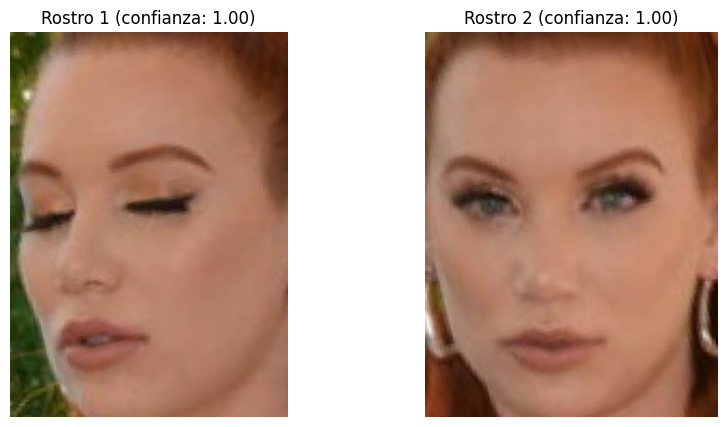


VERIFICACIÓN DE IDENTIDAD
¿Misma persona?: SÍ
Distancia: 0.2002 (umbral: 0.3000)
Modelo usado: Facenet512

ANÁLISIS DE ATRIBUTOS


Action: age:   0%|          | 0/4 [00:00<?, ?it/s]    

26-09-02 18:13:25 - 🔗 age_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5 to /root/.deepface/weights/age_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5
To: /root/.deepface/weights/age_model_weights.h5

  0%|          | 0.00/539M [00:00<?, ?B/s]
  2%|▏         | 11.0M/539M [00:00<00:06, 78.0MB/s]
  4%|▍         | 21.5M/539M [00:00<00:05, 91.4MB/s]
  6%|▋         | 34.1M/539M [00:00<00:04, 106MB/s] 
  8%|▊         | 45.1M/539M [00:00<00:04, 106MB/s]
 10%|█         | 56.1M/539M [00:00<00:05, 84.1MB/s]
 13%|█▎        | 68.2M/539M [00:00<00:05, 94.0MB/s]
 15%|█▍        | 78.6M/539M [00:00<00:04, 96.5MB/s]
 17%|█▋        | 89.1M/539M [00:00<00:04, 95.3MB/s]
 18%|█▊        | 99.1M/539M [00:01<00:04, 92.9MB/s]
 20%|██        | 109M/539M [00:01<00:04, 93.3MB/s] 
 22%|██▏       | 120M/539M [00:01<00:04, 96.1MB/s]
 24%|██▍       | 131M/539M [00:01<00:04, 102MB/s] 
 26%|██▋       | 142M/539M [00:01<00:05, 74.5MB/s]
 29%|██▊       | 154M/539M [00:01<00:04, 85.9MB/s]
 31%|███       | 166M/539M [00:01<00:03, 94.1MB/s]
 33%|███▎      | 177M/53

26-09-02 18:13:36 - 🔗 gender_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/gender_model_weights.h5 to /root/.deepface/weights/gender_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/gender_model_weights.h5
To: /root/.deepface/weights/gender_model_weights.h5

  0%|          | 0.00/537M [00:00<?, ?B/s]
  1%|          | 4.19M/537M [00:00<00:14, 37.4MB/s]
  2%|▏         | 8.39M/537M [00:00<00:14, 35.9MB/s]
  2%|▏         | 12.1M/537M [00:00<00:16, 31.6MB/s]
  5%|▌         | 27.8M/537M [00:00<00:06, 74.4MB/s]
  7%|▋         | 37.7M/537M [00:00<00:06, 82.3MB/s]
 10%|▉         | 53.0M/537M [00:00<00:05, 92.4MB/s]
 12%|█▏        | 66.6M/537M [00:00<00:04, 104MB/s] 
 16%|█▌        | 83.9M/537M [00:00<00:03, 124MB/s]
 18%|█▊        | 97.0M/537M [00:01<00:04, 110MB/s]
 21%|██        | 112M/537M [00:01<00:03, 119MB/s] 
 24%|██▎       | 126M/537M [00:01<00:03, 108MB/s]
 26%|██▌       | 141M/537M [00:01<00:03, 116MB/s]
 29%|██▉       | 155M/537M [00:01<00:03, 124MB/s]
 31%|███▏      | 168M/537M [00:01<00:03, 105MB/s]
 33%|███▎      | 180M/537M [00:01<00:03, 107MB/s]
 36%|███▌      | 195M/537

26-09-02 18:13:46 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5

  0%|          | 0.00/5.98M [00:00<?, ?B/s]
100%|██████████| 5.98M/5.98M [00:00<00:00, 16.6MB/s]
Action: race:  75%|███████▌  | 3/4 [00:21<00:06,  6.02s/it]   

26-09-02 18:13:47 - 🔗 race_model_single_batch.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/race_model_single_batch.h5 to /root/.deepface/weights/race_model_single_batch.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/race_model_single_batch.h5
To: /root/.deepface/weights/race_model_single_batch.h5

  0%|          | 0.00/537M [00:00<?, ?B/s]
  2%|▏         | 11.0M/537M [00:00<00:05, 90.8MB/s]
  5%|▌         | 28.3M/537M [00:00<00:03, 135MB/s] 
  8%|▊         | 42.5M/537M [00:00<00:04, 104MB/s]
 10%|█         | 54.0M/537M [00:00<00:04, 104MB/s]
 13%|█▎        | 69.7M/537M [00:00<00:03, 121MB/s]
 15%|█▌        | 82.8M/537M [00:00<00:03, 123MB/s]
 18%|█▊        | 95.9M/537M [00:00<00:04, 110MB/s]
 20%|██        | 110M/537M [00:00<00:03, 118MB/s] 
 23%|██▎       | 123M/537M [00:01<00:03, 121MB/s]
 25%|██▌       | 137M/537M [00:01<00:03, 109MB/s]
 28%|██▊       | 150M/537M [00:01<00:03, 114MB/s]
 30%|███       | 162M/537M [00:01<00:03, 114MB/s]
 33%|███▎      | 178M/537M [00:01<00:02, 125MB/s]
 36%|███▌      | 191M/537M [00:01<00:03, 108MB/s]
 38%|███▊      | 202M/537M [00:01<00:03, 109MB/s]
 40%|███▉      | 214M/537M


--- Atributos Imagen 1 ---
Edad estimada: 28
Género: Woman (99.8%)
Emoción: neutral

--- Atributos Imagen 2 ---
Edad estimada: 28
Género: Woman (100.0%)
Emoción: neutral

--- Diferencias ---
Diferencia de edad estimada: 0 años
¿Mismo género detectado?: Sí
¿Misma emoción dominante?: Sí


In [ ]:
from deepface import DeepFace
import cv2
import matplotlib.pyplot as plt
import numpy as np


class FaceComparator:
    def __init__(self, path1, path2, model_name="Facenet512", detector="retinaface"):
        self.path1 = path1
        self.path2 = path2
        self.model_name = model_name
        self.detector = detector
        self.img1 = cv2.imread(path1)
        self.img2 = cv2.imread(path2)

    # ---------- DETECTAR ROSTROS ----------
    def detect_faces(self):
        try:
            faces1 = DeepFace.extract_faces(self.path1, detector_backend=self.detector, enforce_detection=False)
            faces2 = DeepFace.extract_faces(self.path2, detector_backend=self.detector, enforce_detection=False)
        except Exception as e:
            print(f"Error detectando rostros: {e}")
            return None, None
        return faces1, faces2

    # ---------- VERIFICACIÓN: ¿ES LA MISMA PERSONA? ----------
    def verify_identity(self):
        try:
            result = DeepFace.verify(
                img1_path=self.path1,
                img2_path=self.path2,
                model_name=self.model_name,
                detector_backend=self.detector,
                distance_metric="cosine"
            )
        except Exception as e:
            print(f"No se pudo verificar (¿hay rostro en ambas imágenes?): {e}")
            return None

        similitud_pct = round((1 - result['distance'] / result['threshold']) * 100, 2) if result['distance'] < result['threshold'] else round(max(0, 100 - result['distance']*100), 2)

        print(f"¿Misma persona?: {'SÍ' if result['verified'] else 'NO'}")
        print(f"Distancia: {result['distance']:.4f} (umbral: {result['threshold']:.4f})")
        print(f"Modelo usado: {result['model']}")
        return result

    # ---------- ANÁLISIS DE ATRIBUTOS (edad, género, emoción, etnia) ----------
    def analyze_attributes(self, img_path):
        try:
            analysis = DeepFace.analyze(
                img_path=img_path,
                actions=['age', 'gender', 'emotion', 'race'],
                detector_backend=self.detector,
                enforce_detection=False
            )
            return analysis[0] if isinstance(analysis, list) else analysis
        except Exception as e:
            print(f"No se pudo analizar atributos de {img_path}: {e}")
            return None

    # ---------- COMPARAR ATRIBUTOS ENTRE LAS DOS IMÁGENES ----------
    def compare_attributes(self):
        a1 = self.analyze_attributes(self.path1)
        a2 = self.analyze_attributes(self.path2)

        if a1 is None or a2 is None:
            return None

        print("\n--- Atributos Imagen 1 ---")
        print(f"Edad estimada: {a1['age']}")
        print(f"Género: {a1['dominant_gender']} ({a1['gender'][a1['dominant_gender']]:.1f}%)")
        print(f"Emoción: {a1['dominant_emotion']}")

        print("\n--- Atributos Imagen 2 ---")
        print(f"Edad estimada: {a2['age']}")
        print(f"Género: {a2['dominant_gender']} ({a2['gender'][a2['dominant_gender']]:.1f}%)")
        print(f"Emoción: {a2['dominant_emotion']}")

        print("\n--- Diferencias ---")
        print(f"Diferencia de edad estimada: {abs(a1['age'] - a2['age'])} años")
        print(f"¿Mismo género detectado?: {'Sí' if a1['dominant_gender'] == a2['dominant_gender'] else 'No'}")
        print(f"¿Misma emoción dominante?: {'Sí' if a1['dominant_emotion'] == a2['dominant_emotion'] else 'No'}")

        return {"img1": a1, "img2": a2}

    # ---------- VISUALIZAR ROSTROS DETECTADOS ----------
    def plot_faces(self):
        faces1, faces2 = self.detect_faces()
        if not faces1 or not faces2:
            print("No se detectaron rostros en una o ambas imágenes.")
            return

        fig, axs = plt.subplots(1, 2, figsize=(10, 5))
        axs[0].imshow(faces1[0]['face'])
        axs[0].set_title(f"Rostro 1 (confianza: {faces1[0]['confidence']:.2f})")
        axs[1].imshow(faces2[0]['face'])
        axs[1].set_title(f"Rostro 2 (confianza: {faces2[0]['confidence']:.2f})")
        for ax in axs: ax.axis('off')
        plt.show()

    # ---------- PIPELINE COMPLETO ----------
    def run(self):
        print("=" * 50)
        print("DETECCIÓN DE ROSTROS")
        print("=" * 50)
        self.plot_faces()

        print("\n" + "=" * 50)
        print("VERIFICACIÓN DE IDENTIDAD")
        print("=" * 50)
        self.verify_identity()

        print("\n" + "=" * 50)
        print("ANÁLISIS DE ATRIBUTOS")
        print("=" * 50)
        self.compare_attributes()


# Uso
fc = FaceComparator("image1.jpg", "image2.jpg", model_name="Facenet512", detector="retinaface")
fc.run()

In [ ]:
!pip install insightface onnxruntime opencv-python-headless matplotlib scipy numpy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 762.2/762.2 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 75.7 MB/s eta 0:00:00


Cargando modelo (la primera vez descarga ~350MB, puede tardar un poco)...
download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:06<00:00, 42287.59KB/s]


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)
Modelo listo

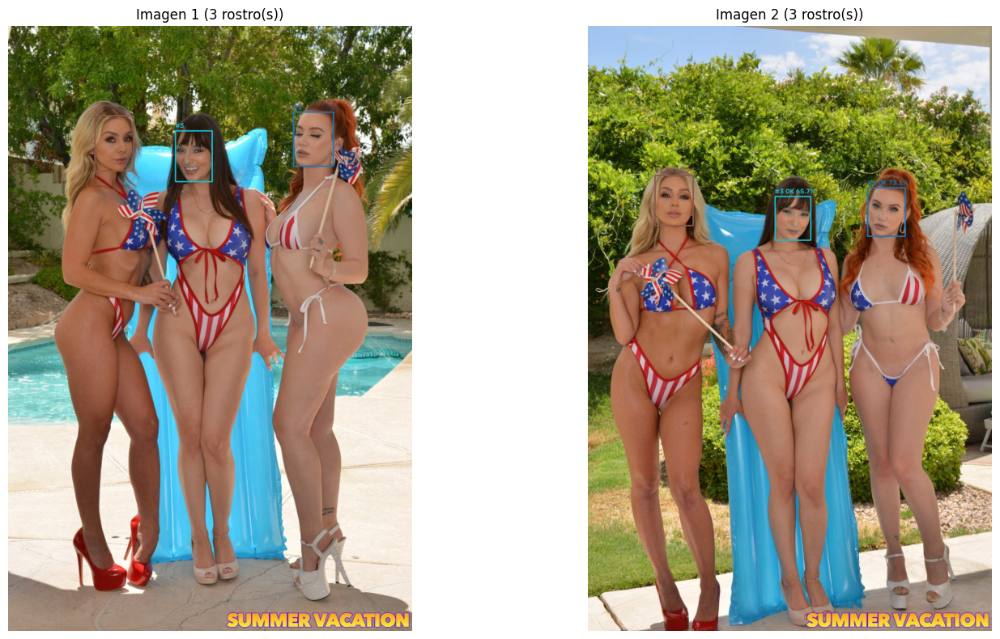

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import linear_sum_assignment
import insightface
from insightface.app import FaceAnalysis


class FaceComparatorPro:
    def __init__(self, path1, path2, det_size=(640, 640), match_threshold=0.45):
        """
        match_threshold: umbral de similitud coseno (0 a 1) para decidir 'misma persona'.
        Con el modelo buffalo_l, >0.45 suele ser la misma persona, <0.20 personas distintas.
        Entre medio es zona ambigua.
        """
        self.path1, self.path2 = path1, path2
        self.match_threshold = match_threshold

        print("Cargando modelo (la primera vez descarga ~350MB, puede tardar un poco)...")
        self.app = FaceAnalysis(name="buffalo_l", providers=["CPUExecutionProvider"])
        self.app.prepare(ctx_id=0, det_size=det_size)
        print("Modelo listo.\n")

        self.img1_bgr = cv2.imread(path1)
        self.img2_bgr = cv2.imread(path2)
        if self.img1_bgr is None or self.img2_bgr is None:
            raise FileNotFoundError("No se pudo leer una de las dos imágenes, revisa la ruta.")

        self.img1_rgb = cv2.cvtColor(self.img1_bgr, cv2.COLOR_BGR2RGB)
        self.img2_rgb = cv2.cvtColor(self.img2_bgr, cv2.COLOR_BGR2RGB)

    # ---------- 1. DETECCIÓN COMPLETA (rostro + landmarks + embedding + edad/género) ----------
    def detect_all(self):
        self.faces1 = self.app.get(self.img1_bgr)
        self.faces2 = self.app.get(self.img2_bgr)
        print(f"Rostros detectados → Imagen 1: {len(self.faces1)} | Imagen 2: {len(self.faces2)}")
        return self.faces1, self.faces2

    # ---------- 2. MATRIZ DE SIMILITUD (coseno entre embeddings de 512-d) ----------
    @staticmethod
    def cosine_sim(a, b):
        return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

    def build_similarity_matrix(self):
        n, m = len(self.faces1), len(self.faces2)
        sim_matrix = np.zeros((n, m))
        for i in range(n):
            for j in range(m):
                sim_matrix[i, j] = self.cosine_sim(self.faces1[i].embedding, self.faces2[j].embedding)
        return sim_matrix

    # ---------- 3. EMPAREJAMIENTO ÓPTIMO (algoritmo húngaro sobre 1-similitud) ----------
    def match_faces(self):
        if not self.faces1 or not self.faces2:
            self.matches, self.sin_pareja_1, self.sin_pareja_2 = [], list(range(len(self.faces1))), list(range(len(self.faces2)))
            return self.matches

        sim_matrix = self.build_similarity_matrix()
        cost_matrix = 1 - sim_matrix  # húngaro minimiza costo, así que usamos 1-similitud
        row_ind, col_ind = linear_sum_assignment(cost_matrix)

        matches, used1, used2 = [], set(), set()
        for i, j in zip(row_ind, col_ind):
            sim = sim_matrix[i, j]
            matches.append({
                "idx1": i, "idx2": j,
                "similitud": round(sim, 4),
                "similitud_pct": round(sim * 100, 1),
                "misma_persona": bool(sim >= self.match_threshold),
            })
            used1.add(i); used2.add(j)

        self.matches = sorted(matches, key=lambda m: -m["similitud"])
        self.sin_pareja_1 = [i for i in range(len(self.faces1)) if i not in used1]
        self.sin_pareja_2 = [j for j in range(len(self.faces2)) if j not in used2]
        return self.matches

    # ---------- 4. PROPORCIONES FACIALES A PARTIR DE LOS 106 LANDMARKS ----------
    @staticmethod
    def compute_proportions(face):
        lm = face.landmark_2d_106
        if lm is None:
            return None

        def d(i, j):
            return float(np.linalg.norm(lm[i] - lm[j]))

        # Índices del esquema de 106 puntos de InsightFace
        face_width   = d(0, 32)     # contorno izquierdo-derecho de la mandíbula
        face_height  = d(16, 82)    # mentón a entre-cejas aprox
        eye_dist     = d(38, 88)    # centro ojo izq - centro ojo der (aprox)
        nose_width   = d(55, 65)
        mouth_width  = d(84, 90)

        if face_width == 0:
            return None

        return {
            "ratio_alto_ancho_cara": round(face_height / face_width, 3),
            "ratio_ojos_ancho_cara": round(eye_dist / face_width, 3),
            "ratio_nariz_ancho_cara": round(nose_width / face_width, 3),
            "ratio_boca_ancho_cara": round(mouth_width / face_width, 3),
        }

    # ---------- 5. REPORTE DETALLADO ----------
    def full_report(self):
        self.detect_all()
        self.match_faces()

        print("\n" + "=" * 65)
        print("REPORTE DETALLADO DE COMPARACIÓN")
        print("=" * 65)

        for rank, m in enumerate(self.matches, 1):
            f1, f2 = self.faces1[m["idx1"]], self.faces2[m["idx2"]]

            print(f"\n{'─'*65}")
            print(f"PAR {rank}: Rostro #{m['idx1']+1} (Imagen 1) ↔ Rostro #{m['idx2']+1} (Imagen 2)")
            print(f"{'─'*65}")
            veredicto = "MISMA PERSONA" if m["misma_persona"] else "PERSONAS DISTINTAS"
            print(f"  Veredicto:        {veredicto}")
            print(f"  Similitud facial: {m['similitud_pct']}%  (umbral usado: {self.match_threshold*100:.0f}%)")

            print(f"\n  -- Imagen 1 --")
            print(f"  Edad estimada:  {int(f1.age)} años")
            print(f"  Género:         {'Hombre' if f1.sex == 'M' else 'Mujer'}")
            print(f"  Score detección: {f1.det_score:.3f}")

            print(f"\n  -- Imagen 2 --")
            print(f"  Edad estimada:  {int(f2.age)} años")
            print(f"  Género:         {'Hombre' if f2.sex == 'M' else 'Mujer'}")
            print(f"  Score detección: {f2.det_score:.3f}")

            print(f"\n  -- Diferencias --")
            print(f"  Diferencia de edad estimada: {abs(int(f1.age) - int(f2.age))} años")
            print(f"  ¿Mismo género detectado?: {'Sí' if f1.sex == f2.sex else 'No'}")

            prop1 = self.compute_proportions(f1)
            prop2 = self.compute_proportions(f2)
            if prop1 and prop2:
                print(f"\n  -- Proporciones faciales (normalizadas por ancho de cara) --")
                for k in prop1:
                    diff_pct = abs(prop1[k] - prop2[k]) / prop1[k] * 100 if prop1[k] != 0 else 0
                    flag = " ⚠ diferencia notable" if diff_pct > 15 else ""
                    print(f"  {k:28s}: img1={prop1[k]:.3f} | img2={prop2[k]:.3f} | Δ={diff_pct:.1f}%{flag}")

        if self.sin_pareja_1:
            print(f"\n{'─'*65}")
            print(f"Rostros SOLO en Imagen 1 (sin correspondencia): {[i+1 for i in self.sin_pareja_1]}")
            for i in self.sin_pareja_1:
                f = self.faces1[i]
                print(f"  Rostro #{i+1}: edad≈{int(f.age)}, género={'Hombre' if f.sex=='M' else 'Mujer'}")

        if self.sin_pareja_2:
            print(f"\n{'─'*65}")
            print(f"Rostros SOLO en Imagen 2 (sin correspondencia): {[j+1 for j in self.sin_pareja_2]}")
            for j in self.sin_pareja_2:
                f = self.faces2[j]
                print(f"  Rostro #{j+1}: edad≈{int(f.age)}, género={'Hombre' if f.sex=='M' else 'Mujer'}")

        print("\n" + "=" * 65)
        print(f"RESUMEN: {len(self.faces1)} rostro(s) en img1, {len(self.faces2)} en img2, "
              f"{sum(1 for m in self.matches if m['misma_persona'])} coinciden como misma persona.")
        print("=" * 65)

    # ---------- 6. VISUALIZACIÓN ----------
    def plot(self, show_landmarks=True):
        img1_draw, img2_draw = self.img1_rgb.copy(), self.img2_rgb.copy()
        colors = plt.cm.tab10(np.linspace(0, 1, max(len(self.matches), 1)))

        def draw_face(img, face, color_bgr, label):
            x1, y1, x2, y2 = face.bbox.astype(int)
            cv2.rectangle(img, (x1, y1), (x2, y2), color_bgr, 3)
            cv2.putText(img, label, (x1, max(y1 - 10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color_bgr, 2)
            if show_landmarks and face.landmark_2d_106 is not None:
                for (px, py) in face.landmark_2d_106.astype(int):
                    cv2.circle(img, (px, py), 1, color_bgr, -1)

        for idx, m in enumerate(self.matches):
            color = tuple(int(c * 255) for c in colors[idx][:3])
            label1 = f"#{idx+1}"
            label2 = f"#{idx+1} {'OK' if m['misma_persona'] else 'DIF'} {m['similitud_pct']}%"
            draw_face(img1_draw, self.faces1[m["idx1"]], color, label1)
            draw_face(img2_draw, self.faces2[m["idx2"]], color, label2)

        for i in self.sin_pareja_1:
            draw_face(img1_draw, self.faces1[i], (255, 0, 0), "solo aqui")
        for j in self.sin_pareja_2:
            draw_face(img2_draw, self.faces2[j], (255, 0, 0), "solo aqui")

        fig, axs = plt.subplots(1, 2, figsize=(16, 8))
        axs[0].imshow(img1_draw); axs[0].set_title(f"Imagen 1 ({len(self.faces1)} rostro(s))")
        axs[1].imshow(img2_draw); axs[1].set_title(f"Imagen 2 ({len(self.faces2)} rostro(s))")
        for ax in axs: ax.axis('off')
        plt.tight_layout()
        plt.show()

    # ---------- PIPELINE COMPLETO ----------
    def run(self):
        self.full_report()
        self.plot()


# ============ USO ============
fc = FaceComparatorPro("image1.jpg", "image2.jpg", match_threshold=0.45)
fc.run()

In [ ]:
!pip install ultralytics opencv-python-headless matplotlib scikit-learn -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.7 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Cargando modelo de pose (descarga ~6MB la primera vez)...
Personas detectadas: 3

ANÁLISIS DE ROPA Y PROPORCIONES — image1.jpg

Persona #1
----------------------------------------
  Parte superior (torso): color gris RGB(166, 104, 74)
  Parte inferior (piernas): color marrón RGB(112, 61, 44)
  Proporciones corporales (relativas, no cm reales):
    ancho_hombros_px: 195.9
    ratio_cadera_hombro: 0.74
    ratio_torso_hombro: 2.23
    ratio_pierna_hombro: 3.98
    altura_aprox_px: 1399.0999755859375

Persona #2
----------------------------------------
  Parte superior (torso): color gris RGB(168, 131, 117)
  Parte inferior (piernas): color gris RGB(162, 114, 94)
  Proporciones corpor

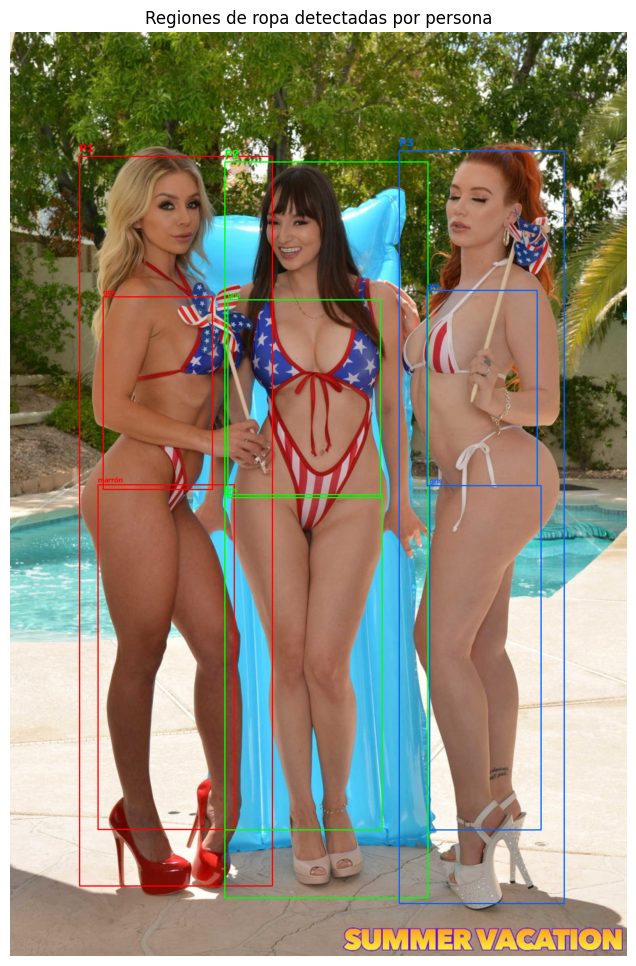

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from sklearn.cluster import KMeans


class PersonClothingAnalyzer:
    def __init__(self, img_path, pose_model="yolov8n-pose.pt"):
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")

        print("Cargando modelo de pose (descarga ~6MB la primera vez)...")
        self.pose_model = YOLO(pose_model)

        # Nombres de colores de referencia para clasificar el color dominante
        self.color_names = {
            "negro": (0, 0, 0), "blanco": (255, 255, 255), "gris": (128, 128, 128),
            "rojo": (200, 30, 30), "azul": (30, 60, 180), "azul_marino": (20, 30, 80),
            "verde": (40, 130, 60), "amarillo": (220, 200, 40), "naranja": (220, 120, 30),
            "rosa": (230, 130, 170), "morado": (120, 50, 150), "marrón": (110, 70, 40),
            "beige": (210, 190, 150), "celeste": (130, 190, 230)
        }

    # ---------- 1. DETECTAR PERSONAS + KEYPOINTS DE POSE ----------
    def detect_people(self, conf=0.4):
        results = self.pose_model(self.img_bgr, conf=conf, verbose=False)[0]
        self.people = []

        if results.keypoints is None or len(results.boxes) == 0:
            print("No se detectaron personas.")
            return []

        for i, (box, kpts) in enumerate(zip(results.boxes, results.keypoints)):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()  # 17 keypoints COCO
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            self.people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf})

        print(f"Personas detectadas: {len(self.people)}")
        return self.people

    # ---------- 2. REGIONES DE ROPA A PARTIR DE KEYPOINTS COCO ----------
    # COCO keypoints: 0 nariz,5 hombro_izq,6 hombro_der,11 cadera_izq,12 cadera_der,
    #                 13 rodilla_izq,14 rodilla_der,15 tobillo_izq,16 tobillo_der
    def get_clothing_regions(self, person):
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        regions = {}

        # Torso (camiseta/blusa/campera): entre hombros y caderas
        if valid(5) and valid(6) and valid(11) and valid(12):
            xs = [kp[5][0], kp[6][0], kp[11][0], kp[12][0]]
            ys = [kp[5][1], kp[6][1], kp[11][1], kp[12][1]]
            pad_x = (max(xs) - min(xs)) * 0.15
            regions["torso"] = (
                int(min(xs) - pad_x), int(min(ys)),
                int(max(xs) + pad_x), int(max(ys))
            )

        # Piernas (pantalón/falda): entre caderas y tobillos
        if valid(11) and valid(12):
            y_top = kp[11][1]
            hip_xs = [kp[11][0], kp[12][0]]
            if valid(15) and valid(16):
                y_bottom = max(kp[15][1], kp[16][1])
            elif valid(13) and valid(14):
                y_bottom = max(kp[13][1], kp[14][1])
            else:
                y_bottom = y_top + (person["bbox"][3] - y_top) * 0.7
            pad_x = abs(hip_xs[1] - hip_xs[0]) * 0.5 + 15
            regions["piernas"] = (
                int(min(hip_xs) - pad_x), int(y_top),
                int(max(hip_xs) + pad_x), int(y_bottom)
            )

        return regions

    # ---------- 3. COLOR DOMINANTE DE UNA REGIÓN ----------
    def get_dominant_color(self, region_box, k=3):
        x1, y1, x2, y2 = region_box
        h, w = self.img_rgb.shape[:2]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        crop = self.img_rgb[y1:y2, x1:x2]

        if crop.size == 0 or crop.shape[0] < 5 or crop.shape[1] < 5:
            return None, None

        pixels = crop.reshape(-1, 3).astype(float)

        # Filtrar píxeles muy oscuros/claros extremos (sombras/brillos) para no sesgar el color
        brightness = pixels.mean(axis=1)
        mask = (brightness > 15) & (brightness < 240)
        if mask.sum() > 20:
            pixels = pixels[mask]

        kmeans = KMeans(n_clusters=min(k, len(pixels)), n_init=5, random_state=42)
        labels = kmeans.fit_predict(pixels)
        counts = np.bincount(labels)
        dominant_rgb = kmeans.cluster_centers_[np.argmax(counts)]

        return dominant_rgb, self._closest_color_name(dominant_rgb)

    def _closest_color_name(self, rgb):
        best_name, best_dist = None, float("inf")
        for name, ref_rgb in self.color_names.items():
            dist = np.linalg.norm(np.array(rgb) - np.array(ref_rgb))
            if dist < best_dist:
                best_dist, best_name = dist, name
        return best_name

    # ---------- 4. PROPORCIONES CORPORALES RELATIVAS (no cm absolutos) ----------
    def get_body_proportions(self, person):
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        def dist(i, j):
            return float(np.linalg.norm(kp[i] - kp[j]))

        # Usamos el ancho de hombros como unidad de referencia relativa
        if not (valid(5) and valid(6)):
            return None
        shoulder_width = dist(5, 6)
        if shoulder_width == 0:
            return None

        props = {"ancho_hombros_px": round(shoulder_width, 1)}

        if valid(11) and valid(12):
            hip_width = dist(11, 12)
            props["ratio_cadera_hombro"] = round(hip_width / shoulder_width, 2)

        if valid(5) and valid(11):
            torso_len = dist(5, 11)
            props["ratio_torso_hombro"] = round(torso_len / shoulder_width, 2)

        if valid(11) and valid(15):
            leg_len = dist(11, 15)
            props["ratio_pierna_hombro"] = round(leg_len / shoulder_width, 2)

        # Estatura aproximada en píxeles (nariz a tobillo promedio) — NO es cm real
        if valid(0) and (valid(15) or valid(16)):
            ankle_y = kp[15][1] if valid(15) else kp[16][1]
            props["altura_aprox_px"] = round(abs(ankle_y - kp[0][1]), 1)

        return props

    # ---------- 5. REPORTE COMPLETO ----------
    def analyze(self):
        self.detect_people()
        self.results = []

        for i, person in enumerate(self.people):
            regions = self.get_clothing_regions(person)
            props = self.get_body_proportions(person)

            clothing = {}
            for region_name, box in regions.items():
                rgb, name = self.get_dominant_color(box)
                if rgb is not None:
                    clothing[region_name] = {"color": name, "rgb": tuple(int(c) for c in rgb), "box": box}

            self.results.append({"idx": i, "clothing": clothing, "proportions": props, "bbox": person["bbox"]})

        return self.results

    def print_report(self):
        print("\n" + "=" * 60)
        print(f"ANÁLISIS DE ROPA Y PROPORCIONES — {self.img_path}")
        print("=" * 60)
        for r in self.results:
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 40)
            if "torso" in r["clothing"]:
                print(f"  Parte superior (torso): color {r['clothing']['torso']['color']} "
                      f"RGB{r['clothing']['torso']['rgb']}")
            if "piernas" in r["clothing"]:
                print(f"  Parte inferior (piernas): color {r['clothing']['piernas']['color']} "
                      f"RGB{r['clothing']['piernas']['rgb']}")
            if r["proportions"]:
                print(f"  Proporciones corporales (relativas, no cm reales):")
                for k, v in r["proportions"].items():
                    print(f"    {k}: {v}")

    # ---------- 6. VISUALIZACIÓN ----------
    def plot(self):
        img_draw = self.img_rgb.copy()
        colors_box = [(255, 0, 0), (0, 255, 0), (0, 100, 255), (255, 165, 0), (180, 0, 255)]

        for r in self.results:
            c = colors_box[r["idx"] % len(colors_box)]
            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)
            cv2.putText(img_draw, f"P{r['idx']+1}", (x1, max(y1-10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, c, 2)
            for region_name, info in r["clothing"].items():
                bx1, by1, bx2, by2 = info["box"]
                cv2.rectangle(img_draw, (bx1, by1), (bx2, by2), c, 2)
                cv2.putText(img_draw, info["color"], (bx1, by1 - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, c, 2)

        plt.figure(figsize=(10, 12))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title("Regiones de ropa detectadas por persona")
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============
analyzer = PersonClothingAnalyzer("image1.jpg")
analyzer.run()

In [ ]:
!pip install transformers torch scikit-image -q

In [ ]:
!pip install ultralytics opencv-python-headless matplotlib scikit-learn transformers torch scikit-image -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.9 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Cargando modelo de pose (descarga ~6MB la primera vez)...
Cargando CLIP para clasificación de prendas (puede tardar la primera vez)...


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Modelos listos.

Personas detectadas: 3

ANÁLISIS DE ROPA Y PROPORCIONES — image1.jpg

Persona #1
----------------------------------------
  Parte superior: sueter — color tostado/canela RGB(166, 104, 74)
    (alternativas: [('sueter', 19.2), ('campera', 13.3), ('vestido', 10.3)])
  Parte inferior: short — color marrón RGB(112, 61, 44)
    (alternativas: [('short', 57.2), ('legging', 17.6), ('pantalon deportivo', 7.1)])
  Proporciones corporales (relativas, no cm reales):
    ancho_hombros_px: 195.9
    ratio_cadera_hombro: 0.74
    ratio_torso_hombro: 2.23
    ratio_pierna_hombro: 3.98
    altura_aprox_px: 1399.0999755859375

Persona #2
----------------------------------------
  Parte superior: vestido — color marrón claro/camel RGB(168, 131, 117)
    (alternativas: [('vestido', 13.7), ('campera', 11.7), ('top deportivo', 11.5)])
  Parte inferior: short — color tostado/canela RGB(162, 114, 94)
    (alternativas: [('short', 30.7), ('falda', 23.6), ('vestido', 14.0)])
  Proporciones cor

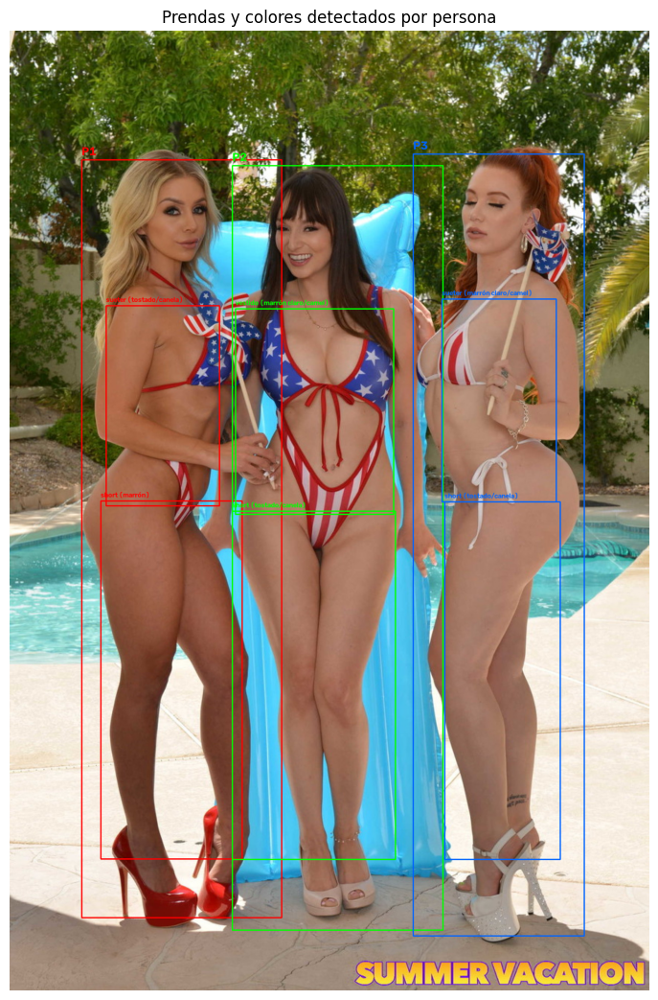

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from sklearn.cluster import KMeans
from transformers import CLIPProcessor, CLIPModel
from skimage.color import rgb2lab
from PIL import Image


class PersonClothingAnalyzer:
    def __init__(self, img_path, pose_model="yolov8n-pose.pt"):
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)

        print("Cargando modelo de pose (descarga ~6MB la primera vez)...")
        self.pose_model = YOLO(pose_model)

        print("Cargando CLIP para clasificación de prendas (puede tardar la primera vez)...")
        self.clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
        self.clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        print("Modelos listos.\n")

        self.torso_labels = [
            "camiseta", "remera", "camisa", "blusa", "sueter", "chompa",
            "chaqueta", "campera", "abrigo", "saco", "hoodie con capucha",
            "vestido", "traje formal", "top deportivo", "chaleco"
        ]
        self.piernas_labels = [
            "pantalon largo", "jean", "short", "bermuda", "falda", "vestido",
            "pantalon deportivo", "legging", "pantalon de vestir formal"
        ]

        self.color_names = {
            "negro": (20, 20, 20), "blanco": (245, 245, 245), "gris claro": (180, 180, 180),
            "gris": (128, 128, 128), "gris oscuro": (80, 80, 80),
            "rojo": (200, 30, 30), "rojo oscuro/vino": (110, 20, 30),
            "azul": (30, 60, 180), "azul marino": (20, 30, 80), "celeste": (130, 190, 230),
            "verde": (40, 130, 60), "verde oliva": (100, 110, 50),
            "amarillo": (220, 200, 40), "naranja": (220, 120, 30),
            "rosa": (230, 130, 170), "morado": (120, 50, 150),
            "marrón": (110, 70, 40), "marrón claro/camel": (170, 120, 80),
            "beige": (210, 190, 150), "tostado/canela": (166, 104, 74),
            "denim/jean": (70, 90, 120)
        }
        self._color_names_lab = {
            name: rgb2lab(np.array([[rgb]], dtype=np.uint8) / 255.0)[0, 0]
            for name, rgb in self.color_names.items()
        }

    # ---------- 1. DETECTAR PERSONAS + KEYPOINTS DE POSE ----------
    def detect_people(self, conf=0.4):
        results = self.pose_model(self.img_bgr, conf=conf, verbose=False)[0]
        self.people = []

        if results.keypoints is None or len(results.boxes) == 0:
            print("No se detectaron personas.")
            return []

        for box, kpts in zip(results.boxes, results.keypoints):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            self.people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf})

        print(f"Personas detectadas: {len(self.people)}")
        return self.people

    # ---------- 2. REGIONES DE ROPA ----------
    def get_clothing_regions(self, person):
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        regions = {}

        if valid(5) and valid(6) and valid(11) and valid(12):
            xs = [kp[5][0], kp[6][0], kp[11][0], kp[12][0]]
            ys = [kp[5][1], kp[6][1], kp[11][1], kp[12][1]]
            pad_x = (max(xs) - min(xs)) * 0.15
            regions["torso"] = (
                int(min(xs) - pad_x), int(min(ys)),
                int(max(xs) + pad_x), int(max(ys))
            )

        if valid(11) and valid(12):
            y_top = kp[11][1]
            hip_xs = [kp[11][0], kp[12][0]]
            if valid(15) and valid(16):
                y_bottom = max(kp[15][1], kp[16][1])
            elif valid(13) and valid(14):
                y_bottom = max(kp[13][1], kp[14][1])
            else:
                y_bottom = y_top + (person["bbox"][3] - y_top) * 0.7
            pad_x = abs(hip_xs[1] - hip_xs[0]) * 0.5 + 15
            regions["piernas"] = (
                int(min(hip_xs) - pad_x), int(y_top),
                int(max(hip_xs) + pad_x), int(y_bottom)
            )

        return regions

    # ---------- 3. COLOR DOMINANTE (Lab, perceptualmente correcto) ----------
    def get_dominant_color(self, region_box, k=3):
        x1, y1, x2, y2 = region_box
        h, w = self.img_rgb.shape[:2]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        crop = self.img_rgb[y1:y2, x1:x2]

        if crop.size == 0 or crop.shape[0] < 5 or crop.shape[1] < 5:
            return None, None

        pixels = crop.reshape(-1, 3).astype(float)
        brightness = pixels.mean(axis=1)
        mask = (brightness > 15) & (brightness < 240)
        if mask.sum() > 20:
            pixels = pixels[mask]

        kmeans = KMeans(n_clusters=min(k, len(pixels)), n_init=5, random_state=42)
        labels = kmeans.fit_predict(pixels)
        counts = np.bincount(labels)
        dominant_rgb = kmeans.cluster_centers_[np.argmax(counts)]

        return dominant_rgb, self._closest_color_name(dominant_rgb)

    def _closest_color_name(self, rgb):
        lab = rgb2lab(np.array([[rgb]], dtype=np.uint8) / 255.0)[0, 0]
        best_name, best_dist = None, float("inf")
        for name, ref_lab in self._color_names_lab.items():
            dist = np.linalg.norm(lab - ref_lab)
            if dist < best_dist:
                best_dist, best_name = dist, name
        return best_name

    # ---------- 4. TIPO DE PRENDA con CLIP zero-shot ----------
    def classify_clothing_type(self, region_box, candidate_labels):
        x1, y1, x2, y2 = region_box
        h, w = self.img_rgb.shape[:2]
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        crop = self.img_rgb[y1:y2, x1:x2]

        if crop.size == 0 or crop.shape[0] < 10 or crop.shape[1] < 10:
            return None, None

        pil_img = Image.fromarray(crop)
        prompts = [f"una foto de ropa: {label}" for label in candidate_labels]

        inputs = self.clip_processor(text=prompts, images=pil_img, return_tensors="pt", padding=True)
        with torch.no_grad():
            outputs = self.clip_model(**inputs)
            probs = outputs.logits_per_image.softmax(dim=1)[0]

        best_idx = probs.argmax().item()
        top3_idx = probs.argsort(descending=True)[:3]
        top3 = [(candidate_labels[i], round(probs[i].item() * 100, 1)) for i in top3_idx]

        return candidate_labels[best_idx], top3

    # ---------- 5. PROPORCIONES CORPORALES RELATIVAS ----------
    def get_body_proportions(self, person):
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        def dist(i, j):
            return float(np.linalg.norm(kp[i] - kp[j]))

        if not (valid(5) and valid(6)):
            return None
        shoulder_width = dist(5, 6)
        if shoulder_width == 0:
            return None

        props = {"ancho_hombros_px": round(shoulder_width, 1)}

        if valid(11) and valid(12):
            props["ratio_cadera_hombro"] = round(dist(11, 12) / shoulder_width, 2)
        if valid(5) and valid(11):
            props["ratio_torso_hombro"] = round(dist(5, 11) / shoulder_width, 2)
        if valid(11) and valid(15):
            props["ratio_pierna_hombro"] = round(dist(11, 15) / shoulder_width, 2)
        if valid(0) and (valid(15) or valid(16)):
            ankle_y = kp[15][1] if valid(15) else kp[16][1]
            props["altura_aprox_px"] = round(abs(ankle_y - kp[0][1]), 1)

        return props

    # ---------- 6. ANÁLISIS COMPLETO ----------
    def analyze(self):
        self.detect_people()
        self.results = []

        for i, person in enumerate(self.people):
            regions = self.get_clothing_regions(person)
            props = self.get_body_proportions(person)

            clothing = {}
            for region_name, box in regions.items():
                rgb, color_name = self.get_dominant_color(box)
                labels = self.torso_labels if region_name == "torso" else self.piernas_labels
                tipo, top3 = self.classify_clothing_type(box, labels)

                if rgb is not None:
                    clothing[region_name] = {
                        "color": color_name,
                        "rgb": tuple(int(c) for c in rgb),
                        "box": box,
                        "tipo_prenda": tipo,
                        "top3_tipos": top3
                    }

            self.results.append({"idx": i, "clothing": clothing, "proportions": props, "bbox": person["bbox"]})

        return self.results

    def print_report(self):
        print("\n" + "=" * 60)
        print(f"ANÁLISIS DE ROPA Y PROPORCIONES — {self.img_path}")
        print("=" * 60)
        for r in self.results:
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 40)
            if "torso" in r["clothing"]:
                c = r["clothing"]["torso"]
                print(f"  Parte superior: {c['tipo_prenda']} — color {c['color']} RGB{c['rgb']}")
                print(f"    (alternativas: {c['top3_tipos']})")
            if "piernas" in r["clothing"]:
                c = r["clothing"]["piernas"]
                print(f"  Parte inferior: {c['tipo_prenda']} — color {c['color']} RGB{c['rgb']}")
                print(f"    (alternativas: {c['top3_tipos']})")
            if r["proportions"]:
                print(f"  Proporciones corporales (relativas, no cm reales):")
                for k, v in r["proportions"].items():
                    print(f"    {k}: {v}")

    # ---------- 7. VISUALIZACIÓN ----------
    def plot(self):
        img_draw = self.img_rgb.copy()
        colors_box = [(255, 0, 0), (0, 255, 0), (0, 100, 255), (255, 165, 0), (180, 0, 255)]

        for r in self.results:
            c = colors_box[r["idx"] % len(colors_box)]
            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)
            cv2.putText(img_draw, f"P{r['idx']+1}", (x1, max(y1-10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, c, 2)
            for region_name, info in r["clothing"].items():
                bx1, by1, bx2, by2 = info["box"]
                cv2.rectangle(img_draw, (bx1, by1), (bx2, by2), c, 2)
                label = f"{info['tipo_prenda']} ({info['color']})"
                cv2.putText(img_draw, label, (bx1, max(by1 - 8, 12)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)

        plt.figure(figsize=(11, 13))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title("Prendas y colores detectados por persona")
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============
analyzer = PersonClothingAnalyzer("image1.jpg")
analyzer.run()

In [ ]:
!pip install ultralytics opencv-python-headless matplotlib -q

Cargando modelo de pose...
Personas detectadas: 3

ANÁLISIS DE PROPORCIONES FÍSICAS — image1.jpg
Modo de calibración: aproximada_por_cara
⚠ Sin objeto de referencia: las medidas en cm son APROXIMADAS
  (usan el ancho promedio de cara humana, ±2-4 cm de error típico,
  y más si la persona está angulada respecto a la cámara).

Persona #1
---------------------------------------------
  ancho_hombros_px: 195.9
  ancho_hombros_cm: 18.5
  ancho_caderas_px: 144.4
  ancho_caderas_cm: 13.600000381469727
  brazo_superior_izq_px: 252.1
  brazo_superior_izq_cm: 23.799999237060547
  antebrazo_izq_px: 64.6
  antebrazo_izq_cm: 6.099999904632568
  torso_izq_px: 437.6
  torso_izq_cm: 41.29999923706055
  muslo_izq_px: 381.0
  muslo_izq_cm: 36.0
  pantorrilla_izq_px: 399.8
  pantorrilla_izq_cm: 37.79999923706055
  estatura_aprox_px: 1511.0
  estatura_aprox_cm: 142.6999969482422

  Somatotipo estimado: MESOMORFO
  Puntajes: {'ectomorfo': 1, 'mesomorfo': 2, 'endomorfo': 0}
    - Hombros notablemente más an

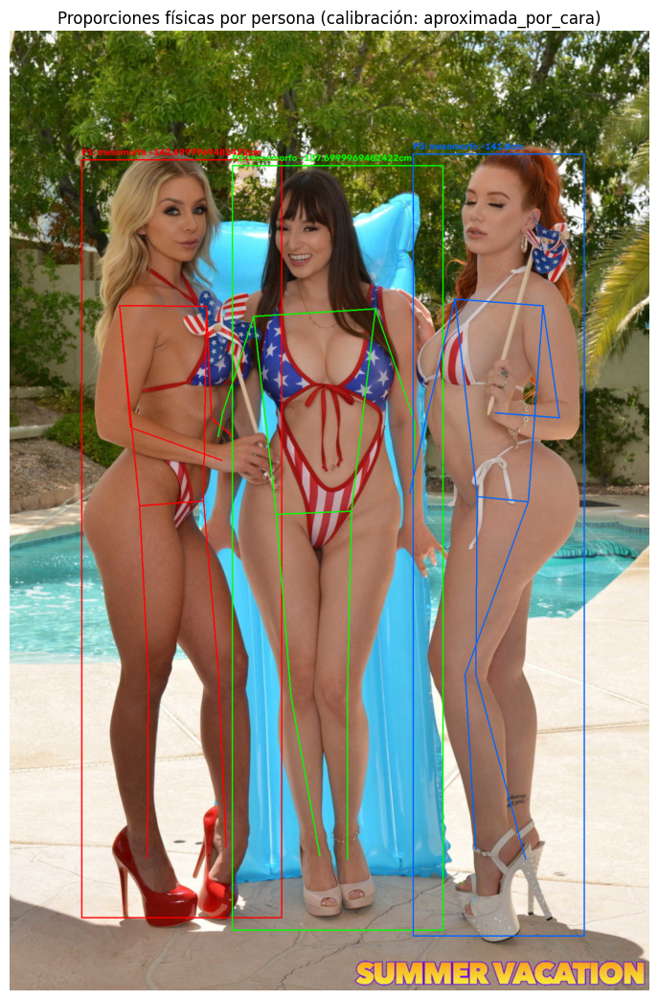

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO


class BodyPhysiqueAnalyzer:
    # Ancho promedio de cara humana adulta (entre pómulos), usado SOLO como
    # respaldo cuando no hay objeto de referencia. Es una aproximación poblacional,
    # no una medida exacta de la persona en la foto.
    AVG_FACE_WIDTH_CM = 14.0

    def __init__(self, img_path, pose_model="yolov8n-pose.pt",
                 ref_pixel_width=None, ref_cm_width=None):
        """
        ref_pixel_width / ref_cm_width: si tienes un objeto de referencia en la foto
        (ej. una tarjeta de crédito = 8.56 cm de ancho), pasa cuántos píxeles mide
        ese objeto en la imagen y su tamaño real en cm. Esto da conversión px->cm
        PRECISA. Si no los pasas, se usa una calibración aproximada (menos confiable).
        """
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)

        print("Cargando modelo de pose...")
        self.pose_model = YOLO(pose_model)

        self.ref_pixel_width = ref_pixel_width
        self.ref_cm_width = ref_cm_width
        self.calibration_mode = "objeto_referencia" if (ref_pixel_width and ref_cm_width) else "aproximada_por_cara"

    # ---------- 1. DETECCIÓN DE PERSONAS + POSE ----------
    def detect_people(self, conf=0.4):
        results = self.pose_model(self.img_bgr, conf=conf, verbose=False)[0]
        self.people = []
        if results.keypoints is None or len(results.boxes) == 0:
            print("No se detectaron personas.")
            return []
        for box, kpts in zip(results.boxes, results.keypoints):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            self.people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf})
        print(f"Personas detectadas: {len(self.people)}")
        return self.people

    # ---------- 2. FACTOR DE CONVERSIÓN PX -> CM ----------
    def get_px_to_cm_factor(self, person):
        """
        Si hay objeto de referencia: usa esa escala (misma para toda la imagen,
        asumiendo que todas las personas están a distancia similar de la cámara).
        Si no: aproxima usando el ancho de cara de ESTA persona vs el promedio
        poblacional (menos preciso, sirve solo como orden de magnitud).
        """
        if self.calibration_mode == "objeto_referencia":
            return self.ref_cm_width / self.ref_pixel_width

        # Fallback: ancho de cara vía keypoints de orejas (3,4) u ojos (1,2)
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        if valid(3) and valid(4):  # orejas
            face_px = np.linalg.norm(kp[3] - kp[4])
        elif valid(1) and valid(2):  # ojos
            face_px = np.linalg.norm(kp[1] - kp[2]) * 2.2  # ojos a ancho de cara ~2.2x
        else:
            return None

        if face_px <= 0:
            return None
        return self.AVG_FACE_WIDTH_CM / face_px

    # ---------- 3. MEDIDAS EN PÍXELES Y CM ----------
    def get_measurements(self, person):
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        def dist(i, j):
            return float(np.linalg.norm(kp[i] - kp[j]))

        px_to_cm = self.get_px_to_cm_factor(person)
        m = {"_px_to_cm_factor": px_to_cm, "_modo_calibracion": self.calibration_mode}

        def add(name, i, j):
            if valid(i) and valid(j):
                px = dist(i, j)
                m[f"{name}_px"] = round(px, 1)
                if px_to_cm:
                    m[f"{name}_cm"] = round(px * px_to_cm, 1)

        # COCO keypoints: 0 nariz,1-2 ojos,3-4 orejas,5-6 hombros,7-8 codos,
        # 9-10 muñecas,11-12 caderas,13-14 rodillas,15-16 tobillos
        add("ancho_hombros", 5, 6)
        add("ancho_caderas", 11, 12)
        add("brazo_superior_izq", 5, 7)
        add("antebrazo_izq", 7, 9)
        add("torso_izq", 5, 11)
        add("muslo_izq", 11, 13)
        add("pantorrilla_izq", 13, 15)

        # Estatura aproximada: nariz a tobillo (no es 100% la altura real, falta cabeza y pie)
        if valid(0) and (valid(15) or valid(16)):
            ankle_y = kp[15][1] if valid(15) else kp[16][1]
            altura_px = abs(ankle_y - kp[0][1]) * 1.08  # factor para compensar cabeza/pie no medidos
            m["estatura_aprox_px"] = round(altura_px, 1)
            if px_to_cm:
                m["estatura_aprox_cm"] = round(altura_px * px_to_cm, 1)

        return m

    # ---------- 4. CLASIFICACIÓN DE SOMATOTIPO (tipo de físico) ----------
    def classify_physique(self, m):
        """
        Estimación de somatotipo basada en ratios corporales (no en apariencia visual
        de grasa/músculo, que una IA de visión no puede medir con certeza desde una foto).
        Usa las 3 categorías clásicas de Sheldon como aproximación orientativa:
        - Ectomorfo: hombros y caderas angostos relativo a la altura, extremidades largas
        - Mesomorfo: hombros notablemente más anchos que caderas, torso proporcionado
        - Endomorfo: caderas anchas relativo a hombros, torso más corto relativo a piernas
        """
        if "ancho_hombros_px" not in m or "ancho_caderas_px" not in m:
            return {"tipo": "Indeterminado", "razon": "Faltan puntos clave (hombros/caderas) para estimar."}

        shoulder = m["ancho_hombros_px"]
        hip = m["ancho_caderas_px"]
        shoulder_hip_ratio = shoulder / hip if hip else None

        torso = m.get("torso_izq_px")
        muslo = m.get("muslo_izq_px")
        pantorrilla = m.get("pantorrilla_izq_px")
        pierna_total = (muslo or 0) + (pantorrilla or 0)
        torso_pierna_ratio = (torso / pierna_total) if (torso and pierna_total) else None

        scores = {"ectomorfo": 0, "mesomorfo": 0, "endomorfo": 0}
        detalles = []

        if shoulder_hip_ratio is not None:
            if shoulder_hip_ratio >= 1.35:
                scores["mesomorfo"] += 2
                detalles.append(f"Hombros notablemente más anchos que caderas (ratio {shoulder_hip_ratio:.2f}) → rasgo mesomorfo")
            elif shoulder_hip_ratio <= 1.05:
                scores["endomorfo"] += 2
                detalles.append(f"Hombros y caderas de ancho similar (ratio {shoulder_hip_ratio:.2f}) → rasgo endomorfo")
            else:
                scores["ectomorfo"] += 1
                detalles.append(f"Ratio hombro/cadera moderado ({shoulder_hip_ratio:.2f}) → rasgo ectomorfo/neutro")

        if torso_pierna_ratio is not None:
            if torso_pierna_ratio < 0.75:
                scores["ectomorfo"] += 1
                detalles.append(f"Piernas largas relativo al torso (ratio {torso_pierna_ratio:.2f}) → rasgo ectomorfo")
            elif torso_pierna_ratio > 0.95:
                scores["endomorfo"] += 1
                detalles.append(f"Torso largo relativo a piernas (ratio {torso_pierna_ratio:.2f}) → rasgo endomorfo")
            else:
                scores["mesomorfo"] += 1
                detalles.append(f"Proporción torso/pierna equilibrada ({torso_pierna_ratio:.2f}) → rasgo mesomorfo")

        tipo_dominante = max(scores, key=scores.get)
        return {"tipo": tipo_dominante, "scores": scores, "detalles": detalles}

    # ---------- 5. ANÁLISIS COMPLETO ----------
    def analyze(self):
        self.detect_people()
        self.results = []

        for i, person in enumerate(self.people):
            m = self.get_measurements(person)
            physique = self.classify_physique(m)
            self.results.append({"idx": i, "measurements": m, "physique": physique, "bbox": person["bbox"]})

        return self.results

    def print_report(self):
        print("\n" + "=" * 65)
        print(f"ANÁLISIS DE PROPORCIONES FÍSICAS — {self.img_path}")
        print(f"Modo de calibración: {self.calibration_mode}")
        if self.calibration_mode == "aproximada_por_cara":
            print("⚠ Sin objeto de referencia: las medidas en cm son APROXIMADAS")
            print("  (usan el ancho promedio de cara humana, ±2-4 cm de error típico,")
            print("  y más si la persona está angulada respecto a la cámara).")
        print("=" * 65)

        for r in self.results:
            m = r["measurements"]
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 45)
            for key, val in m.items():
                if key.startswith("_"):
                    continue
                print(f"  {key}: {val}")

            print(f"\n  Somatotipo estimado: {r['physique']['tipo'].upper()}")
            if "scores" in r["physique"]:
                print(f"  Puntajes: {r['physique']['scores']}")
                for d in r["physique"]["detalles"]:
                    print(f"    - {d}")
            else:
                print(f"  ({r['physique']['razon']})")

    # ---------- 6. VISUALIZACIÓN ----------
    def plot(self):
        img_draw = self.img_rgb.copy()
        colors_box = [(255, 0, 0), (0, 255, 0), (0, 100, 255), (255, 165, 0), (180, 0, 255)]
        skeleton = [(5,6),(5,7),(7,9),(6,8),(8,10),(5,11),(6,12),(11,12),
                    (11,13),(13,15),(12,14),(14,16)]

        for r in self.results:
            c = colors_box[r["idx"] % len(colors_box)]
            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)
            label = f"P{r['idx']+1}: {r['physique']['tipo']}"
            if "estatura_aprox_cm" in r["measurements"]:
                label += f" ~{r['measurements']['estatura_aprox_cm']}cm"
            cv2.putText(img_draw, label, (x1, max(y1-10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)

            kp = self.people[r["idx"]]["keypoints"]
            kp_conf = self.people[r["idx"]]["kp_conf"]
            for i, j in skeleton:
                if kp_conf[i] > 0.3 and kp_conf[j] > 0.3:
                    p1, p2 = tuple(kp[i].astype(int)), tuple(kp[j].astype(int))
                    cv2.line(img_draw, p1, p2, c, 2)

        plt.figure(figsize=(11, 13))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title(f"Proporciones físicas por persona (calibración: {self.calibration_mode})")
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============

# OPCIÓN A: sin objeto de referencia (aproximado, usa ancho de cara promedio)
analyzer = BodyPhysiqueAnalyzer("image1.jpg")
analyzer.run()

# OPCIÓN B: con objeto de referencia para cm REALES y precisos
# Ejemplo: si en la foto hay una tarjeta de crédito (8.56 cm de ancho real)
# que en la imagen mide 120 píxeles de ancho:
#
# analyzer = BodyPhysiqueAnalyzer("image1.jpg", ref_pixel_width=120, ref_cm_width=8.56)
# analyzer.run()

In [ ]:
!pip install ultralytics opencv-python-headless matplotlib -q

Cargando modelos de pose y segmentación...
Modelos listos.

Personas detectadas: 3

ANÁLISIS DE FORMA CORPORAL — image2.jpg
Calibración: sin_calibrar
⚠ Medidas en cm son aproximadas (sin objeto de referencia)

Persona #1
---------------------------------------------
  ancho_hombros_px: 330
  ancho_hombros_cm: 28.600000381469727
  ancho_cintura_px: 398
  ancho_cintura_cm: 34.5
  ancho_caderas_px: 317
  ancho_caderas_cm: 27.399999618530273

  Forma corporal: MANZANA / OVALADO
    - Hombro: 330px | Cintura: 398px | Cadera: 317px
    - Diferencia hombro-cadera: 3.9%
    - Ratio cintura/cadera: 1.26
    - Ratio cintura/hombro: 1.21
    - La cintura es casi tan ancha como hombros y caderas → forma manzana

Persona #2
---------------------------------------------
  ancho_hombros_px: 339
  ancho_hombros_cm: 33.29999923706055
  ancho_cintura_px: 336
  ancho_cintura_cm: 33.099998474121094
  ancho_caderas_px: 377
  ancho_caderas_cm: 37.099998474121094

  Forma corporal: PERA / TRIÁNGULO
    - Hom

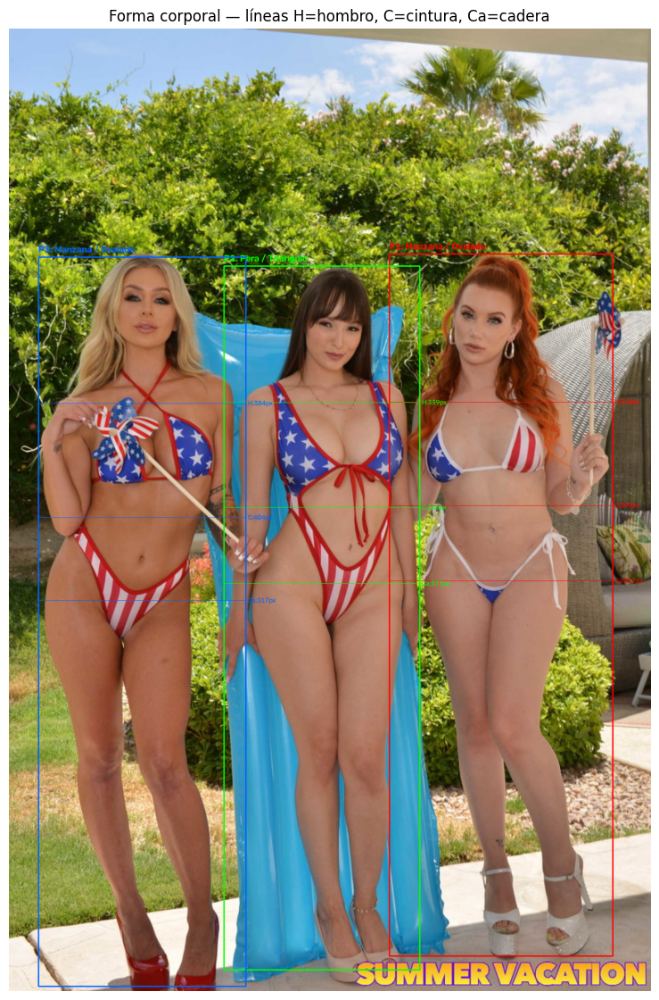

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO


class BodyShapeAnalyzer:
    def __init__(self, img_path, pose_model="yolov8n-pose.pt", seg_model="yolov8n-seg.pt",
                 ref_pixel_width=None, ref_cm_width=None):
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)

        print("Cargando modelos de pose y segmentación...")
        self.pose_model = YOLO(pose_model)
        self.seg_model = YOLO(seg_model)  # para obtener la silueta real del cuerpo
        print("Modelos listos.\n")

        self.ref_pixel_width = ref_pixel_width
        self.ref_cm_width = ref_cm_width
        self.calibration_mode = "objeto_referencia" if (ref_pixel_width and ref_cm_width) else "sin_calibrar"

    # ---------- 1. POSE (para ubicar niveles de hombro/cintura/cadera) ----------
    def detect_pose(self, conf=0.4):
        results = self.pose_model(self.img_bgr, conf=conf, verbose=False)[0]
        self.people = []
        if results.keypoints is None or len(results.boxes) == 0:
            print("No se detectaron personas.")
            return []
        for box, kpts in zip(results.boxes, results.keypoints):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            self.people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf})
        print(f"Personas detectadas: {len(self.people)}")
        return self.people

    # ---------- 2. SEGMENTACIÓN (silueta real de cada persona) ----------
    def detect_masks(self, conf=0.4):
        results = self.seg_model(self.img_bgr, conf=conf, classes=[0], verbose=False)[0]  # clase 0 = persona
        self.masks = []
        if results.masks is None:
            print("No se detectaron máscaras de segmentación.")
            return []
        h, w = self.img_bgr.shape[:2]
        for mask_data, box in zip(results.masks.data, results.boxes):
            mask = mask_data.cpu().numpy()
            mask_resized = cv2.resize(mask, (w, h))
            self.masks.append({
                "mask": (mask_resized > 0.5).astype(np.uint8),
                "bbox": box.xyxy[0].cpu().numpy().astype(int)
            })
        return self.masks

    # ---------- 3. EMPAREJAR CADA PERSONA (pose) CON SU MÁSCARA (segmentación) ----------
    def match_pose_to_mask(self, person):
        px1, py1, px2, py2 = person["bbox"]
        center = np.array([(px1 + px2) / 2, (py1 + py2) / 2])
        best_mask, best_dist = None, float("inf")
        for m in self.masks:
            mx1, my1, mx2, my2 = m["bbox"]
            mcenter = np.array([(mx1 + mx2) / 2, (my1 + my2) / 2])
            dist = np.linalg.norm(center - mcenter)
            if dist < best_dist:
                best_dist, best_mask = dist, m
        return best_mask

    # ---------- 4. ANCHO REAL DEL CUERPO EN UNA FILA (y) USANDO LA MÁSCARA ----------
    def get_width_at_y(self, mask, y, x_range=None):
        h, w = mask.shape
        y = int(np.clip(y, 0, h - 1))
        row = mask[y, :]
        if x_range:
            x0, x1 = x_range
            row = row.copy()
            row[:max(0, x0)] = 0
            row[min(w, x1):] = 0
        xs = np.where(row > 0)[0]
        if len(xs) == 0:
            return None, None, None
        return int(xs.max() - xs.min()), int(xs.min()), int(xs.max())

    # ---------- 5. MEDIR HOMBRO, CINTURA, CADERA CON LA SILUETA ----------
    def measure_body_shape(self, person, mask_entry):
        kp = person["keypoints"]
        conf = person["kp_conf"]
        mask = mask_entry["mask"]
        mx1, my1, mx2, my2 = mask_entry["bbox"]

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        result = {}

        # Nivel de hombros: promedio de y de ambos hombros (keypoints 5,6)
        if valid(5) and valid(6):
            y_shoulder = int((kp[5][1] + kp[6][1]) / 2)
            w_shoulder, _, _ = self.get_width_at_y(mask, y_shoulder, (mx1, mx2))
            result["ancho_hombros_px"] = w_shoulder
            result["_y_shoulder"] = y_shoulder

        # Nivel de caderas: promedio de y de ambas caderas (keypoints 11,12)
        if valid(11) and valid(12):
            y_hip = int((kp[11][1] + kp[12][1]) / 2)
            w_hip, _, _ = self.get_width_at_y(mask, y_hip, (mx1, mx2))
            result["ancho_caderas_px"] = w_hip
            result["_y_hip"] = y_hip

        # Nivel de cintura: no es un keypoint COCO, se interpola entre hombro y cadera.
        # Anatómicamente la cintura está ~55-60% del camino entre hombro y cadera (más cerca de la cadera).
        if "_y_shoulder" in result and "_y_hip" in result:
            y_waist = int(result["_y_shoulder"] + (result["_y_hip"] - result["_y_shoulder"]) * 0.58)
            w_waist, _, _ = self.get_width_at_y(mask, y_waist, (mx1, mx2))
            result["ancho_cintura_px"] = w_waist
            result["_y_waist"] = y_waist

        return result

    # ---------- 6. CONVERSIÓN PX -> CM ----------
    def get_px_to_cm_factor(self, person):
        if self.calibration_mode == "objeto_referencia":
            return self.ref_cm_width / self.ref_pixel_width

        kp = person["keypoints"]
        conf = person["kp_conf"]
        AVG_FACE_WIDTH_CM = 14.0

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        if valid(3) and valid(4):
            face_px = np.linalg.norm(kp[3] - kp[4])
        elif valid(1) and valid(2):
            face_px = np.linalg.norm(kp[1] - kp[2]) * 2.2
        else:
            return None
        return AVG_FACE_WIDTH_CM / face_px if face_px > 0 else None

    # ---------- 7. CLASIFICACIÓN DE FORMA CORPORAL ----------
    def classify_body_shape(self, m):
        """
        Clasificación estándar basada en ratios hombro/cintura/cadera:
        - Reloj de arena: hombro ≈ cadera, cintura notablemente más angosta que ambos
        - Pera/triángulo: cadera notablemente más ancha que hombro
        - Triángulo invertido: hombro notablemente más ancho que cadera
        - Rectángulo: hombro ≈ cintura ≈ cadera (poca diferencia)
        - Manzana/ovalado: cintura ≈ o más ancha que hombro y cadera
        """
        shoulder = m.get("ancho_hombros_px")
        waist = m.get("ancho_cintura_px")
        hip = m.get("ancho_caderas_px")

        if not (shoulder and waist and hip):
            return {"tipo": "Indeterminado", "razon": "Faltan medidas de hombro/cintura/cadera."}

        shoulder_hip_diff_pct = abs(shoulder - hip) / max(shoulder, hip) * 100
        waist_hip_ratio = waist / hip
        waist_shoulder_ratio = waist / shoulder

        detalles = [
            f"Hombro: {shoulder}px | Cintura: {waist}px | Cadera: {hip}px",
            f"Diferencia hombro-cadera: {shoulder_hip_diff_pct:.1f}%",
            f"Ratio cintura/cadera: {waist_hip_ratio:.2f}",
            f"Ratio cintura/hombro: {waist_shoulder_ratio:.2f}",
        ]

        # Manzana: cintura es casi tan ancha o más que hombro/cadera
        if waist_hip_ratio > 0.90 and waist_shoulder_ratio > 0.90:
            tipo = "Manzana / Ovalado"
            detalles.append("La cintura es casi tan ancha como hombros y caderas → forma manzana")

        # Reloj de arena: hombro y cadera similares, cintura claramente más angosta
        elif shoulder_hip_diff_pct < 8 and waist_hip_ratio < 0.78:
            tipo = "Reloj de arena"
            detalles.append("Hombros y caderas de ancho similar, cintura marcadamente más angosta → reloj de arena")

        # Pera / triángulo: cadera notablemente más ancha que hombro
        elif hip > shoulder and (hip - shoulder) / shoulder * 100 > 8:
            tipo = "Pera / Triángulo"
            detalles.append("Caderas notablemente más anchas que hombros → forma pera")

        # Triángulo invertido: hombro notablemente más ancho que cadera
        elif shoulder > hip and (shoulder - hip) / hip * 100 > 8:
            tipo = "Triángulo invertido"
            detalles.append("Hombros notablemente más anchos que caderas → triángulo invertido")

        # Rectángulo: todo parecido, cintura no muy marcada
        else:
            tipo = "Rectángulo"
            detalles.append("Hombros, cintura y caderas de ancho similar, sin cintura marcada → rectángulo")

        return {"tipo": tipo, "waist_hip_ratio": round(waist_hip_ratio, 2),
                "waist_shoulder_ratio": round(waist_shoulder_ratio, 2), "detalles": detalles}

    # ---------- 8. ANÁLISIS COMPLETO ----------
    def analyze(self):
        self.detect_pose()
        self.detect_masks()
        self.results = []

        for i, person in enumerate(self.people):
            mask_entry = self.match_pose_to_mask(person)
            if mask_entry is None:
                self.results.append({"idx": i, "error": "No se pudo asociar silueta", "bbox": person["bbox"]})
                continue

            m = self.measure_body_shape(person, mask_entry)
            px_to_cm = self.get_px_to_cm_factor(person)

            if px_to_cm:
                for key in ["ancho_hombros_px", "ancho_cintura_px", "ancho_caderas_px"]:
                    if m.get(key):
                        m[key.replace("_px", "_cm")] = round(m[key] * px_to_cm, 1)

            shape = self.classify_body_shape(m)
            self.results.append({
                "idx": i, "measurements": m, "shape": shape,
                "bbox": person["bbox"], "mask": mask_entry["mask"]
            })

        return self.results

    def print_report(self):
        print("\n" + "=" * 65)
        print(f"ANÁLISIS DE FORMA CORPORAL — {self.img_path}")
        print(f"Calibración: {self.calibration_mode}")
        if self.calibration_mode == "sin_calibrar":
            print("⚠ Medidas en cm son aproximadas (sin objeto de referencia)")
        print("=" * 65)

        for r in self.results:
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 45)
            if "error" in r:
                print(f"  {r['error']}")
                continue

            m = r["measurements"]
            for key in ["ancho_hombros_px", "ancho_hombros_cm", "ancho_cintura_px",
                        "ancho_cintura_cm", "ancho_caderas_px", "ancho_caderas_cm"]:
                if key in m:
                    print(f"  {key}: {m[key]}")

            print(f"\n  Forma corporal: {r['shape']['tipo'].upper()}")
            for d in r["shape"]["detalles"]:
                print(f"    - {d}")

    # ---------- 9. VISUALIZACIÓN ----------
    def plot(self):
        img_draw = self.img_rgb.copy()
        colors_box = [(255, 0, 0), (0, 255, 0), (0, 100, 255), (255, 165, 0), (180, 0, 255)]

        for r in self.results:
            if "error" in r:
                continue
            c = colors_box[r["idx"] % len(colors_box)]
            m = r["measurements"]
            mx1, mx2 = r["bbox"][0], r["bbox"][2]

            # Dibujar líneas horizontales en los niveles medidos
            for y_key, w_key, label in [("_y_shoulder", "ancho_hombros_px", "H"),
                                          ("_y_waist", "ancho_cintura_px", "C"),
                                          ("_y_hip", "ancho_caderas_px", "Ca")]:
                if y_key in m and m.get(w_key):
                    y = m[y_key]
                    cv2.line(img_draw, (mx1, y), (mx2, y), c, 1)
                    cv2.putText(img_draw, f"{label}:{m[w_key]}px", (mx2 + 5, y + 5),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1)

            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)
            cv2.putText(img_draw, f"P{r['idx']+1}: {r['shape']['tipo']}", (x1, max(y1 - 10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)

        plt.figure(figsize=(12, 14))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title("Forma corporal — líneas H=hombro, C=cintura, Ca=cadera")
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============

# Sin objeto de referencia (cm aproximados)
analyzer = BodyShapeAnalyzer("image2.jpg")
analyzer.run()

# Con objeto de referencia (cm precisos) — ej. tarjeta de crédito de 8.56cm que mide 120px en la foto
# analyzer = BodyShapeAnalyzer("image1.jpg", ref_pixel_width=120, ref_cm_width=8.56)
# analyzer.run()

Cargando modelos...
Modelos listos.

Personas detectadas: 1

ANÁLISIS DE FORMA CORPORAL (con validación de ángulo) — image4.jpg

Persona #1
--------------------------------------------------
  Vista detectada: 3/4 (girada)  |  Confiabilidad: 55%
    - Nariz descentrada respecto a hombros (6.02) → vista 3/4
  ancho_hombros_px: 124
  ancho_hombros_cm: 21.899999618530273
  ancho_cintura_px: 189
  ancho_cintura_cm: 33.400001525878906
  ancho_caderas_px: 233
  ancho_caderas_cm: 41.20000076293945

  Forma corporal: PERA / TRIÁNGULO
    - Hombro:124px Cintura:189px Cadera:233px
    - cintura/cadera=0.81, cintura/hombro=1.52


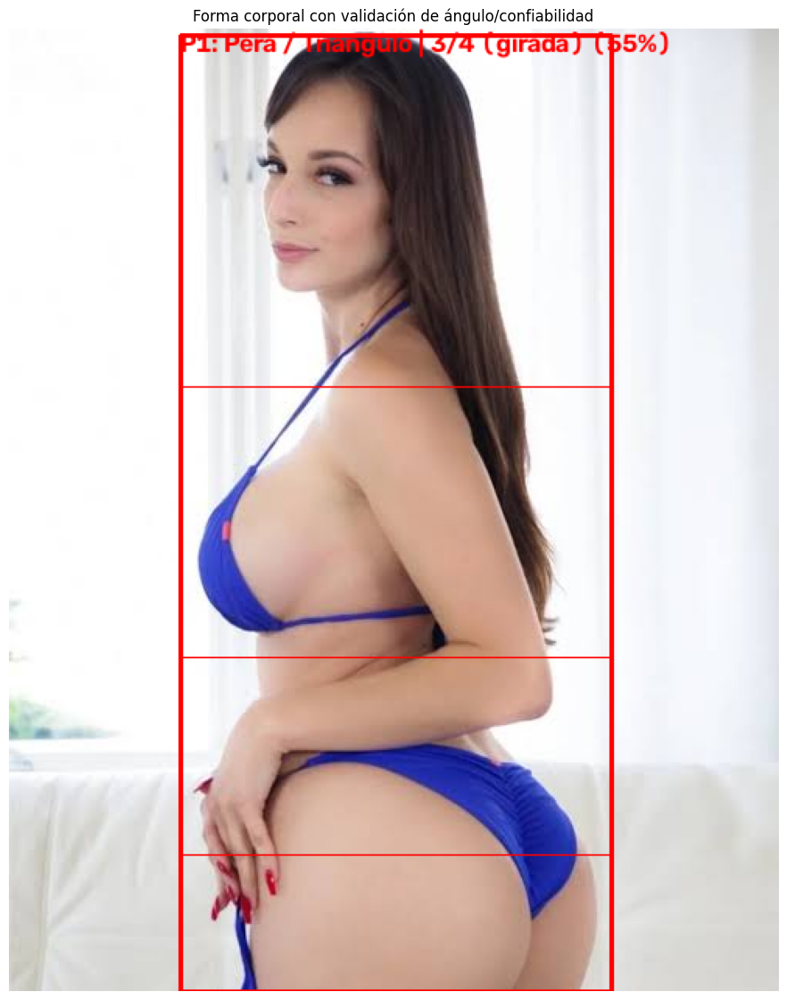

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO


class BodyShapeAnalyzerRobust:
    # Índices COCO
    NOSE, L_EYE, R_EYE, L_EAR, R_EAR = 0, 1, 2, 3, 4
    L_SHOULDER, R_SHOULDER = 5, 6
    L_ELBOW, R_ELBOW = 7, 8
    L_WRIST, R_WRIST = 9, 10
    L_HIP, R_HIP = 11, 12
    L_KNEE, R_KNEE = 13, 14
    L_ANKLE, R_ANKLE = 15, 16

    def __init__(self, img_path, pose_model="yolov8n-pose.pt", seg_model="yolov8n-seg.pt",
                 ref_pixel_width=None, ref_cm_width=None):
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)

        print("Cargando modelos...")
        self.pose_model = YOLO(pose_model)
        self.seg_model = YOLO(seg_model)
        print("Modelos listos.\n")

        self.ref_pixel_width = ref_pixel_width
        self.ref_cm_width = ref_cm_width
        self.calibration_mode = "objeto_referencia" if (ref_pixel_width and ref_cm_width) else "sin_calibrar"

    # ---------- DETECCIÓN BASE ----------
    def detect_pose(self, conf=0.35):
        results = self.pose_model(self.img_bgr, conf=conf, verbose=False)[0]
        self.people = []
        if results.keypoints is None or len(results.boxes) == 0:
            return []
        for box, kpts in zip(results.boxes, results.keypoints):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            self.people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf})
        print(f"Personas detectadas: {len(self.people)}")
        return self.people

    def detect_masks(self, conf=0.35):
        results = self.seg_model(self.img_bgr, conf=conf, classes=[0], verbose=False)[0]
        self.masks = []
        if results.masks is None:
            return []
        h, w = self.img_bgr.shape[:2]
        for mask_data, box in zip(results.masks.data, results.boxes):
            mask = cv2.resize(mask_data.cpu().numpy(), (w, h))
            self.masks.append({"mask": (mask > 0.5).astype(np.uint8),
                                "bbox": box.xyxy[0].cpu().numpy().astype(int)})
        return self.masks

    def match_pose_to_mask(self, person):
        px1, py1, px2, py2 = person["bbox"]
        center = np.array([(px1 + px2) / 2, (py1 + py2) / 2])
        best_mask, best_dist = None, float("inf")
        for m in self.masks:
            mx1, my1, mx2, my2 = m["bbox"]
            mcenter = np.array([(mx1 + mx2) / 2, (my1 + my2) / 2])
            dist = np.linalg.norm(center - mcenter)
            if dist < best_dist:
                best_dist, best_mask = dist, m
        return best_mask

    # ---------- 1. DETECTAR ORIENTACIÓN / ÁNGULO DE LA PERSONA ----------
    def estimate_orientation(self, person):
        """
        Determina si la persona está de frente, perfil, 3/4 o espalda,
        y devuelve un score de confiabilidad (0-1) para las medidas de ancho.
        """
        kp = person["keypoints"]
        conf = person["kp_conf"]

        def valid(idx, min_conf=0.3):
            return conf[idx] > min_conf and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        info = {"vista": "indeterminada", "confiabilidad": 0.0, "razones": []}

        # --- Señal 1: ¿se ven ambos hombros y ambas caderas? (clave para perfil vs frente) ---
        both_shoulders = valid(self.L_SHOULDER) and valid(self.R_SHOULDER)
        both_hips = valid(self.L_HIP) and valid(self.R_HIP)
        both_ears = valid(self.L_EAR) and valid(self.R_EAR)
        both_eyes = valid(self.L_EYE) and valid(self.R_EYE)

        if not both_shoulders:
            info["vista"] = "perfil o muy angulada"
            info["razones"].append("Solo se detecta un hombro con confianza → probable perfil")
            info["confiabilidad"] = 0.15
            return info

        # --- Señal 2: ancho hombro vs ancho de cara (en perfil, el ancho de "cara" colapsa) ---
        shoulder_width = np.linalg.norm(kp[self.L_SHOULDER] - kp[self.R_SHOULDER])
        if both_ears:
            ear_width = np.linalg.norm(kp[self.L_EAR] - kp[self.R_EAR])
        elif both_eyes:
            ear_width = np.linalg.norm(kp[self.L_EYE] - kp[self.R_EYE]) * 1.8
        else:
            ear_width = None

        # --- Señal 3: nariz centrada entre hombros (indica frontalidad) ---
        nose_centering = None
        if valid(self.NOSE):
            mid_shoulder_x = (kp[self.L_SHOULDER][0] + kp[self.R_SHOULDER][0]) / 2
            nose_centering = abs(kp[self.NOSE][0] - mid_shoulder_x) / shoulder_width if shoulder_width else None

        # --- Señal 4: inclinación del eje hombro-cadera respecto a la vertical (persona agachada/torcida) ---
        tilt_deg = None
        if both_shoulders and both_hips:
            mid_shoulder = (kp[self.L_SHOULDER] + kp[self.R_SHOULDER]) / 2
            mid_hip = (kp[self.L_HIP] + kp[self.R_HIP]) / 2
            dx, dy = mid_hip[0] - mid_shoulder[0], mid_hip[1] - mid_shoulder[1]
            tilt_deg = abs(np.degrees(np.arctan2(dx, dy)))

        # --- Decisión combinada ---
        score = 1.0
        if nose_centering is not None:
            if nose_centering > 0.35:
                info["vista"] = "3/4 (girada)"
                info["razones"].append(f"Nariz descentrada respecto a hombros ({nose_centering:.2f}) → vista 3/4")
                score *= 0.6
            else:
                info["razones"].append(f"Nariz centrada respecto a hombros ({nose_centering:.2f}) → vista frontal")

        if not info["razones"]:
            info["vista"] = "frontal (asumida)"

        if info["vista"] == "indeterminada":
            info["vista"] = "frontal (asumida)"

        if tilt_deg is not None:
            if tilt_deg > 15:
                info["razones"].append(f"Torso inclinado {tilt_deg:.1f}° respecto a vertical → postura no erguida")
                score *= max(0.4, 1 - (tilt_deg - 15) / 60)

        if not both_hips:
            info["razones"].append("Caderas no visibles con confianza → no se puede medir cintura/cadera")
            score *= 0.3

        # Penalizar por confianza baja general de los keypoints clave
        key_confs = [conf[i] for i in [self.L_SHOULDER, self.R_SHOULDER, self.L_HIP, self.R_HIP] if conf[i] > 0]
        if key_confs:
            avg_conf = np.mean(key_confs)
            score *= avg_conf

        info["confiabilidad"] = round(float(np.clip(score, 0, 1)), 2)
        info["_tilt_deg"] = tilt_deg
        return info

    # ---------- 2. ANCHO CORREGIDO POR ROTACIÓN EN EL PLANO ----------
    def get_width_at_y_corrected(self, mask, y, x_range, tilt_deg=None):
        """
        Si la persona está inclinada (tilt en el plano de la imagen, no de perfil real),
        el ancho horizontal puro subestima el ancho real del cuerpo. Se corrige dividiendo
        por el coseno de la inclinación. Esto NO corrige el caso de perfil real (rotación
        en profundidad), que ya se filtra aparte con la confiabilidad.
        """
        h, w = mask.shape
        y = int(np.clip(y, 0, h - 1))
        row = mask[y, :].copy()
        x0, x1 = x_range
        row[:max(0, x0)] = 0
        row[min(w, x1):] = 0
        xs = np.where(row > 0)[0]
        if len(xs) == 0:
            return None
        raw_width = int(xs.max() - xs.min())
        if tilt_deg and tilt_deg > 3:
            correction = np.cos(np.radians(min(tilt_deg, 45)))
            return round(raw_width * correction, 1) if correction > 0.3 else raw_width
        return raw_width

    # ---------- 3. MEDIR CON VALIDACIÓN DE CONFIABILIDAD ----------
    def measure_body_shape(self, person, mask_entry, orientation):
        kp = person["keypoints"]
        conf = person["kp_conf"]
        mask = mask_entry["mask"]
        mx1, my1, mx2, my2 = mask_entry["bbox"]
        tilt = orientation.get("_tilt_deg")

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        result = {}

        if valid(self.L_SHOULDER) and valid(self.R_SHOULDER):
            y_shoulder = int((kp[self.L_SHOULDER][1] + kp[self.R_SHOULDER][1]) / 2)
            result["ancho_hombros_px"] = self.get_width_at_y_corrected(mask, y_shoulder, (mx1, mx2), tilt)
            result["_y_shoulder"] = y_shoulder

        if valid(self.L_HIP) and valid(self.R_HIP):
            y_hip = int((kp[self.L_HIP][1] + kp[self.R_HIP][1]) / 2)
            result["ancho_caderas_px"] = self.get_width_at_y_corrected(mask, y_hip, (mx1, mx2), tilt)
            result["_y_hip"] = y_hip

        if "_y_shoulder" in result and "_y_hip" in result:
            y_waist = int(result["_y_shoulder"] + (result["_y_hip"] - result["_y_shoulder"]) * 0.58)
            result["ancho_cintura_px"] = self.get_width_at_y_corrected(mask, y_waist, (mx1, mx2), tilt)
            result["_y_waist"] = y_waist

        return result

    def get_px_to_cm_factor(self, person):
        if self.calibration_mode == "objeto_referencia":
            return self.ref_cm_width / self.ref_pixel_width
        kp, conf = person["keypoints"], person["kp_conf"]
        AVG_FACE_WIDTH_CM = 14.0

        def valid(idx):
            return conf[idx] > 0.3 and not (kp[idx][0] == 0 and kp[idx][1] == 0)

        if valid(self.L_EAR) and valid(self.R_EAR):
            face_px = np.linalg.norm(kp[self.L_EAR] - kp[self.R_EAR])
        elif valid(self.L_EYE) and valid(self.R_EYE):
            face_px = np.linalg.norm(kp[self.L_EYE] - kp[self.R_EYE]) * 2.2
        else:
            return None
        return AVG_FACE_WIDTH_CM / face_px if face_px > 0 else None

    # ---------- 4. CLASIFICACIÓN (solo si confiabilidad suficiente) ----------
    def classify_body_shape(self, m, confiabilidad):
        if confiabilidad < 0.4:
            return {"tipo": "No confiable", "razon": "Ángulo/pose no permite una medición fiable de la silueta."}

        shoulder, waist, hip = m.get("ancho_hombros_px"), m.get("ancho_cintura_px"), m.get("ancho_caderas_px")
        if not (shoulder and waist and hip):
            return {"tipo": "Indeterminado", "razon": "Faltan medidas clave."}

        shoulder_hip_diff_pct = abs(shoulder - hip) / max(shoulder, hip) * 100
        waist_hip_ratio = waist / hip
        waist_shoulder_ratio = waist / shoulder
        detalles = [f"Hombro:{shoulder}px Cintura:{waist}px Cadera:{hip}px",
                    f"cintura/cadera={waist_hip_ratio:.2f}, cintura/hombro={waist_shoulder_ratio:.2f}"]

        if waist_hip_ratio > 0.90 and waist_shoulder_ratio > 0.90:
            tipo = "Manzana / Ovalado"
        elif shoulder_hip_diff_pct < 8 and waist_hip_ratio < 0.78:
            tipo = "Reloj de arena"
        elif hip > shoulder and (hip - shoulder) / shoulder * 100 > 8:
            tipo = "Pera / Triángulo"
        elif shoulder > hip and (shoulder - hip) / hip * 100 > 8:
            tipo = "Triángulo invertido"
        else:
            tipo = "Rectángulo"

        return {"tipo": tipo, "detalles": detalles,
                "waist_hip_ratio": round(waist_hip_ratio, 2)}

    # ---------- 5. PIPELINE COMPLETO ----------
    def analyze(self):
        self.detect_pose()
        self.detect_masks()
        self.results = []

        for i, person in enumerate(self.people):
            orientation = self.estimate_orientation(person)
            mask_entry = self.match_pose_to_mask(person)

            if mask_entry is None:
                self.results.append({"idx": i, "error": "No se pudo asociar silueta", "bbox": person["bbox"],
                                      "orientation": orientation})
                continue

            m = self.measure_body_shape(person, mask_entry, orientation)
            px_to_cm = self.get_px_to_cm_factor(person)
            if px_to_cm:
                for key in ["ancho_hombros_px", "ancho_cintura_px", "ancho_caderas_px"]:
                    if m.get(key):
                        m[key.replace("_px", "_cm")] = round(m[key] * px_to_cm, 1)

            shape = self.classify_body_shape(m, orientation["confiabilidad"])
            self.results.append({"idx": i, "measurements": m, "shape": shape, "orientation": orientation,
                                  "bbox": person["bbox"], "mask": mask_entry["mask"]})
        return self.results

    def print_report(self):
        print("\n" + "=" * 70)
        print(f"ANÁLISIS DE FORMA CORPORAL (con validación de ángulo) — {self.img_path}")
        print("=" * 70)

        for r in self.results:
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 50)
            if "error" in r:
                print(f"  {r['error']}")
                continue

            o = r["orientation"]
            print(f"  Vista detectada: {o['vista']}  |  Confiabilidad: {o['confiabilidad']*100:.0f}%")
            for razon in o["razones"]:
                print(f"    - {razon}")

            if o["confiabilidad"] < 0.4:
                print(f"\n  ⚠ RESULTADO NO CONFIABLE — ángulo/pose no permite medir bien.")
                print(f"    Recomendación: usar una foto de frente, cuerpo completo, postura erguida.")
                continue

            m = r["measurements"]
            for key in ["ancho_hombros_px", "ancho_hombros_cm", "ancho_cintura_px",
                        "ancho_cintura_cm", "ancho_caderas_px", "ancho_caderas_cm"]:
                if key in m:
                    print(f"  {key}: {m[key]}")

            print(f"\n  Forma corporal: {r['shape']['tipo'].upper()}")
            if "detalles" in r["shape"]:
                for d in r["shape"]["detalles"]:
                    print(f"    - {d}")

    def plot(self):
        img_draw = self.img_rgb.copy()
        colors_box = [(255, 0, 0), (0, 255, 0), (0, 100, 255), (255, 165, 0), (180, 0, 255)]

        for r in self.results:
            c = colors_box[r["idx"] % len(colors_box)]
            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)

            o = r["orientation"]
            conf_pct = int(o["confiabilidad"] * 100)
            tipo = r["shape"]["tipo"] if "error" not in r else "sin silueta"
            label = f"P{r['idx']+1}: {tipo} | {o['vista']} ({conf_pct}%)"
            cv2.putText(img_draw, label, (x1, max(y1 - 10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, c, 2)

            if "error" not in r and o["confiabilidad"] >= 0.4:
                m = r["measurements"]
                mx1, mx2 = x1, x2
                for y_key, w_key, lbl in [("_y_shoulder", "ancho_hombros_px", "H"),
                                            ("_y_waist", "ancho_cintura_px", "C"),
                                            ("_y_hip", "ancho_caderas_px", "Ca")]:
                    if y_key in m and m.get(w_key):
                        y = m[y_key]
                        cv2.line(img_draw, (mx1, y), (mx2, y), c, 1)

        plt.figure(figsize=(12, 14))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title("Forma corporal con validación de ángulo/confiabilidad")
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============
analyzer = BodyShapeAnalyzerRobust("image1.jpg")
analyzer.run()

In [ ]:
!pip install ultralytics opencv-python numpy matplotlib scikit-learn mediapipe open_clip_torch torch Pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.6 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0


In [ ]:
"""
PersonProfiler — Análisis robusto de proporciones corporales + atributos visuales.

Combina varios modelos (cada uno opcional / con degradación elegante si no
está instalado) para ser tolerante a pose, ángulo, zoom y recorte parcial:

  - Pose:          YOLOv8-Pose (principal) + MediaPipe Pose (relleno / 3D aprox.)
  - Segmentación:  YOLOv8-Seg (principal) + MediaPipe Selfie Segmentation (fallback)
  - Multi-escala:  reintenta la detección con la imagen re-escalada si falla
                    (soluciona personas muy pequeñas -zoom out- o muy grandes -zoom in-)
  - Proporciones:  hombros / cintura / cadera, con corrección de inclinación
                    y de profundidad (usa z de MediaPipe cuando existe)
  - Cabello:       color dominante (KMeans) + longitud aproximada
  - Piel:          tono dominante (KMeans) sobre parches de piel (cara/antebrazo)
  - Ropa:          tipo + color de prenda superior e inferior
                    (CLIP zero-shot si está disponible; si no, heurística de forma+color)
  - Accesorios:    YOLOv8 COCO (mochila, bolso, corbata, paraguas...) + heurística
                    de lentes/gorro sobre la región de la cara

INSTALACIÓN RECOMENDADA (entorno con internet, no este sandbox):
    pip install ultralytics opencv-python numpy matplotlib scikit-learn
    pip install mediapipe                       # pose/segmentación auxiliar
    pip install open_clip_torch torch           # clasificación de ropa zero-shot
    pip install deepface                        # (opcional) edad/género/emoción

    # pesos que se descargan solos la primera vez que se usan:
    yolov8n-pose.pt, yolov8n-seg.pt, yolov8n.pt  (ultralytics, desde GitHub releases)

Cada bloque de imports está protegido con try/except: si una librería no
está instalada, esa capacidad simplemente se desactiva y se informa en el
reporte final ("no disponible"), en vez de romper todo el pipeline.
"""

import warnings
warnings.filterwarnings("ignore")

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# ---- Dependencias opcionales -------------------------------------------------
try:
    from ultralytics import YOLO
    HAS_YOLO = True
except ImportError:
    HAS_YOLO = False

try:
    import mediapipe as mp
    HAS_MEDIAPIPE = True
except ImportError:
    HAS_MEDIAPIPE = False

try:
    import open_clip
    import torch
    HAS_CLIP = True
except ImportError:
    HAS_CLIP = False


# ============================================================================
# 1. UTILIDADES DE COLOR
# ============================================================================

HAIR_COLOR_TABLE = {
    "negro":        (20, 20, 20),
    "castaño oscuro": (60, 40, 30),
    "castaño":      (100, 65, 45),
    "castaño claro": (140, 100, 70),
    "rubio oscuro": (170, 140, 90),
    "rubio":        (210, 180, 130),
    "rubio claro":  (235, 215, 170),
    "pelirrojo":    (150, 70, 40),
    "gris":         (150, 150, 150),
    "blanco/canoso": (215, 215, 215),
}

SKIN_TONE_TABLE = {
    "muy claro": (245, 220, 200),
    "claro":     (225, 190, 160),
    "medio":     (190, 145, 110),
    "moreno":    (140, 100, 70),
    "oscuro":    (90, 60, 40),
    "muy oscuro": (55, 35, 25),
}

CLOTH_COLOR_NAMES = {
    "negro": (0, 0, 0), "blanco": (255, 255, 255), "gris": (128, 128, 128),
    "rojo": (200, 30, 30), "azul": (30, 60, 200), "azul marino": (20, 30, 80),
    "verde": (40, 140, 60), "amarillo": (230, 210, 40), "naranja": (230, 130, 30),
    "morado": (120, 40, 150), "rosado": (230, 150, 180), "café": (110, 70, 40),
    "beige": (215, 195, 160),
}


def _closest_label(rgb, table):
    rgb = np.array(rgb, dtype=float)
    best, best_d = None, float("inf")
    for name, ref in table.items():
        d = np.linalg.norm(rgb - np.array(ref, dtype=float))
        if d < best_d:
            best, best_d = name, d
    return best


def dominant_color(pixels_rgb, k=3):
    """pixels_rgb: array Nx3. Devuelve el color dominante (ignora outliers)."""
    if pixels_rgb is None or len(pixels_rgb) < k:
        return None
    km = KMeans(n_clusters=min(k, len(pixels_rgb)), n_init=4, random_state=0)
    labels = km.fit_predict(pixels_rgb)
    counts = np.bincount(labels)
    return km.cluster_centers_[np.argmax(counts)]


# ============================================================================
# 2. POSE MULTI-MODELO (YOLO + MediaPipe)
# ============================================================================

class MultiModelPoseEstimator:
    """Ensambla YOLOv8-Pose con MediaPipe Pose para rellenar keypoints faltantes
    y estimar profundidad relativa (mejor detección de perfil / 3-4 / espalda)."""

    COCO_NAMES = ["nose", "l_eye", "r_eye", "l_ear", "r_ear",
                  "l_shoulder", "r_shoulder", "l_elbow", "r_elbow",
                  "l_wrist", "r_wrist", "l_hip", "r_hip",
                  "l_knee", "r_knee", "l_ankle", "r_ankle"]

    def __init__(self, yolo_model="yolov8n-pose.pt"):
        self.yolo = YOLO(yolo_model) if HAS_YOLO else None
        if HAS_MEDIAPIPE:
            self.mp_pose = mp.solutions.pose.Pose(
                static_image_mode=True, model_complexity=2,
                min_detection_confidence=0.3)
        else:
            self.mp_pose = None

    def _detect_yolo(self, img_bgr, conf):
        if self.yolo is None:
            return []
        people = []
        results = self.yolo(img_bgr, conf=conf, verbose=False)[0]
        if results.keypoints is None:
            return []
        for box, kpts in zip(results.boxes, results.keypoints):
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            kp = kpts.xy[0].cpu().numpy()
            kp_conf = kpts.conf[0].cpu().numpy() if kpts.conf is not None else np.ones(17)
            people.append({"bbox": xyxy, "keypoints": kp, "kp_conf": kp_conf, "z": None})
        return people

    def _refine_with_mediapipe(self, img_bgr, person):
        """Usa MediaPipe (dentro del bbox de la persona) para rellenar
        keypoints con confianza baja y obtener una z aproximada (profundidad)."""
        if self.mp_pose is None:
            return person
        x1, y1, x2, y2 = person["bbox"]
        x1, y1 = max(0, x1), max(0, y1)
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            return person
        rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        res = self.mp_pose.process(rgb)
        if not res.pose_landmarks:
            return person

        h, w = crop.shape[:2]
        lm = res.pose_landmarks.landmark
        # Mapeo aproximado MediaPipe(33) -> COCO(17)
        mp_map = {0: 0, 2: 1, 5: 2, 7: 3, 8: 4, 11: 5, 12: 6, 13: 7, 14: 8,
                  15: 9, 16: 10, 23: 11, 24: 12, 25: 13, 26: 14, 27: 15, 28: 16}

        z_vals = np.zeros(17)
        for coco_idx, mp_idx in mp_map.items():
            p = lm[mp_idx]
            visible = p.visibility if hasattr(p, "visibility") else 1.0
            z_vals[coco_idx] = p.z
            if person["kp_conf"][coco_idx] < 0.3 and visible > 0.4:
                person["keypoints"][coco_idx] = [x1 + p.x * w, y1 + p.y * h]
                person["kp_conf"][coco_idx] = visible
        person["z"] = z_vals
        return person

    def detect(self, img_bgr, conf=0.30):
        """Detección con reintento multi-escala: si YOLO no encuentra a nadie
        (persona muy pequeña o muy grande / recortada), se reescala la imagen."""
        people = self._detect_yolo(img_bgr, conf)

        if not people:
            for scale in (1.5, 2.0, 0.6):
                h, w = img_bgr.shape[:2]
                resized = cv2.resize(img_bgr, (int(w * scale), int(h * scale)))
                cand = self._detect_yolo(resized, conf * 0.85)
                if cand:
                    for p in cand:
                        p["bbox"] = (p["bbox"] / scale).astype(int)
                        p["keypoints"] = p["keypoints"] / scale
                    people = cand
                    break

        if HAS_MEDIAPIPE:
            people = [self._refine_with_mediapipe(img_bgr, p) for p in people]

        return people


# ============================================================================
# 3. SEGMENTACIÓN MULTI-MODELO (YOLO-Seg + MediaPipe Selfie Segmentation)
# ============================================================================

class MultiModelSegmenter:
    def __init__(self, yolo_model="yolov8n-seg.pt"):
        self.yolo = YOLO(yolo_model) if HAS_YOLO else None
        if HAS_MEDIAPIPE:
            self.mp_seg = mp.solutions.selfie_segmentation.SelfieSegmentation(model_selection=1)
        else:
            self.mp_seg = None

    def _yolo_masks(self, img_bgr, conf):
        if self.yolo is None:
            return []
        h, w = img_bgr.shape[:2]
        results = self.yolo(img_bgr, conf=conf, classes=[0], verbose=False)[0]
        masks = []
        if results.masks is None:
            return []
        for mask_data, box in zip(results.masks.data, results.boxes):
            m = cv2.resize(mask_data.cpu().numpy(), (w, h))
            masks.append({"mask": (m > 0.5).astype(np.uint8),
                          "bbox": box.xyxy[0].cpu().numpy().astype(int)})
        return masks

    def _mediapipe_mask(self, img_bgr, bbox):
        """Fallback de segmentación por persona, útil si YOLO-seg falla
        (fondo complejo, pose extrema, recorte parcial)."""
        if self.mp_seg is None:
            return None
        x1, y1, x2, y2 = bbox
        h, w = img_bgr.shape[:2]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            return None
        rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        res = self.mp_seg.process(rgb)
        if res.segmentation_mask is None:
            return None
        full = np.zeros((h, w), dtype=np.uint8)
        full[y1:y2, x1:x2] = (res.segmentation_mask > 0.5).astype(np.uint8)
        return {"mask": full, "bbox": np.array([x1, y1, x2, y2])}

    def detect(self, img_bgr, people, conf=0.30):
        masks = self._yolo_masks(img_bgr, conf)
        matched = []
        for person in people:
            best = self._match(person, masks)
            if best is None:
                best = self._mediapipe_mask(img_bgr, person["bbox"])
            matched.append(best)
        return matched

    @staticmethod
    def _match(person, masks):
        if not masks:
            return None
        kp = person["keypoints"]
        valid_pts = kp[np.any(kp != 0, axis=1)]
        if len(valid_pts) == 0:
            return None
        center = valid_pts.mean(axis=0)
        best, best_d = None, float("inf")
        for m in masks:
            mx1, my1, mx2, my2 = m["bbox"]
            mc = np.array([(mx1 + mx2) / 2, (my1 + my2) / 2])
            d = np.linalg.norm(center - mc)
            if d < best_d:
                best, best_d = m, d
        return best


# ============================================================================
# 4. ORIENTACIÓN / CONFIABILIDAD (2D + z de MediaPipe si existe)
# ============================================================================

class OrientationEstimator:
    L_SH, R_SH, L_HIP, R_HIP = 5, 6, 11, 12
    L_EAR, R_EAR, L_EYE, R_EYE, NOSE = 3, 4, 1, 2, 0

    @classmethod
    def estimate(cls, person):
        kp, conf = person["keypoints"], person["kp_conf"]
        z = person.get("z")

        def valid(i, th=0.3):
            return conf[i] > th and not (kp[i][0] == 0 and kp[i][1] == 0)

        info = {"vista": "indeterminada", "confiabilidad": 0.0, "razones": [], "_tilt_deg": None}
        both_sh = valid(cls.L_SH) and valid(cls.R_SH)
        both_hip = valid(cls.L_HIP) and valid(cls.R_HIP)

        if not both_sh:
            info.update(vista="perfil o muy angulada", confiabilidad=0.15,
                        razones=["Solo un hombro visible → probable perfil"])
            return info

        score = 1.0
        shoulder_w = np.linalg.norm(kp[cls.L_SH] - kp[cls.R_SH])

        # Señal extra: si tenemos z de MediaPipe, un delta z grande entre
        # hombros = persona rotada respecto a la cámara (más fiable que 2D solo)
        if z is not None and shoulder_w > 0:
            dz = abs(z[cls.L_SH] - z[cls.R_SH])
            if dz > 0.15:
                info["razones"].append(f"Diferencia de profundidad entre hombros ({dz:.2f}) → vista rotada")
                score *= max(0.3, 1 - dz)

        if valid(cls.NOSE):
            mid_x = (kp[cls.L_SH][0] + kp[cls.R_SH][0]) / 2
            centering = abs(kp[cls.NOSE][0] - mid_x) / shoulder_w if shoulder_w else None
            if centering is not None:
                if centering > 0.35:
                    info["vista"] = "3/4 (girada)"
                    score *= 0.6
                else:
                    info["vista"] = "frontal"

        if info["vista"] == "indeterminada":
            info["vista"] = "frontal (asumida)"

        if both_sh and both_hip:
            mid_sh = (kp[cls.L_SH] + kp[cls.R_SH]) / 2
            mid_hip = (kp[cls.L_HIP] + kp[cls.R_HIP]) / 2
            dx, dy = mid_hip[0] - mid_sh[0], mid_hip[1] - mid_sh[1]
            tilt = abs(np.degrees(np.arctan2(dx, dy)))
            info["_tilt_deg"] = tilt
            if tilt > 15:
                info["razones"].append(f"Torso inclinado {tilt:.1f}°")
                score *= max(0.4, 1 - (tilt - 15) / 60)

        if not both_hip:
            info["razones"].append("Caderas no visibles → sin cintura/cadera fiable")
            score *= 0.3

        key_confs = [conf[i] for i in [cls.L_SH, cls.R_SH, cls.L_HIP, cls.R_HIP] if conf[i] > 0]
        if key_confs:
            score *= np.mean(key_confs)

        info["confiabilidad"] = round(float(np.clip(score, 0, 1)), 2)
        return info


# ============================================================================
# 5. PROPORCIONES CORPORALES (hombros / cintura / cadera)
# ============================================================================

class BodyProportions:
    L_SH, R_SH, L_HIP, R_HIP = 5, 6, 11, 12
    L_EAR, R_EAR, L_EYE, R_EYE = 3, 4, 1, 2

    @staticmethod
    def _width_at_y(mask, y, x_range, tilt_deg=None, n_rows=3):
        """Promedia varias filas alrededor de y para reducir ruido de la máscara."""
        h, w = mask.shape
        widths = []
        for dy in range(-n_rows, n_rows + 1):
            yy = int(np.clip(y + dy, 0, h - 1))
            row = mask[yy, :].copy()
            x0, x1 = x_range
            row[:max(0, x0)] = 0
            row[min(w, x1):] = 0
            xs = np.where(row > 0)[0]
            if len(xs):
                widths.append(xs.max() - xs.min())
        if not widths:
            return None
        raw = float(np.median(widths))
        if tilt_deg and tilt_deg > 3:
            corr = np.cos(np.radians(min(tilt_deg, 45)))
            return round(raw * corr, 1) if corr > 0.3 else raw
        return round(raw, 1)

    @classmethod
    def measure(cls, person, mask_entry, orientation):
        kp, conf = person["keypoints"], person["kp_conf"]
        mask = mask_entry["mask"]
        mx1, my1, mx2, my2 = mask_entry["bbox"]
        tilt = orientation.get("_tilt_deg")

        def valid(i):
            return conf[i] > 0.3 and not (kp[i][0] == 0 and kp[i][1] == 0)

        out = {}
        if valid(cls.L_SH) and valid(cls.R_SH):
            y = int((kp[cls.L_SH][1] + kp[cls.R_SH][1]) / 2)
            out["ancho_hombros_px"] = cls._width_at_y(mask, y, (mx1, mx2), tilt)
            out["_y_shoulder"] = y
        if valid(cls.L_HIP) and valid(cls.R_HIP):
            y = int((kp[cls.L_HIP][1] + kp[cls.R_HIP][1]) / 2)
            out["ancho_caderas_px"] = cls._width_at_y(mask, y, (mx1, mx2), tilt)
            out["_y_hip"] = y
        if "_y_shoulder" in out and "_y_hip" in out:
            y = int(out["_y_shoulder"] + (out["_y_hip"] - out["_y_shoulder"]) * 0.58)
            out["ancho_cintura_px"] = cls._width_at_y(mask, y, (mx1, mx2), tilt)
            out["_y_waist"] = y
        return out

    @staticmethod
    def get_px_to_cm_factor(person, ref_pixel_width=None, ref_cm_width=None):
        if ref_pixel_width and ref_cm_width:
            return ref_cm_width / ref_pixel_width
        kp, conf = person["keypoints"], person["kp_conf"]
        L_EAR, R_EAR, L_EYE, R_EYE = 3, 4, 1, 2

        def valid(i):
            return conf[i] > 0.3 and not (kp[i][0] == 0 and kp[i][1] == 0)

        if valid(L_EAR) and valid(R_EAR):
            face_px = np.linalg.norm(kp[L_EAR] - kp[R_EAR])
        elif valid(L_EYE) and valid(R_EYE):
            face_px = np.linalg.norm(kp[L_EYE] - kp[R_EYE]) * 2.2
        else:
            return None
        AVG_FACE_WIDTH_CM = 14.0
        return AVG_FACE_WIDTH_CM / face_px if face_px > 0 else None

    @staticmethod
    def classify_shape(m, confiabilidad):
        if confiabilidad < 0.4:
            return {"tipo": "No confiable", "razon": "Ángulo/pose no permite medir bien la silueta."}
        s, w, h = m.get("ancho_hombros_px"), m.get("ancho_cintura_px"), m.get("ancho_caderas_px")
        if not (s and w and h):
            return {"tipo": "Indeterminado", "razon": "Faltan medidas clave."}
        sh_diff = abs(s - h) / max(s, h) * 100
        whr, wsr = w / h, w / s
        detalles = [f"Hombro:{s}px Cintura:{w}px Cadera:{h}px",
                    f"cintura/cadera={whr:.2f} cintura/hombro={wsr:.2f}"]
        if whr > 0.90 and wsr > 0.90:
            tipo = "Manzana / Ovalado"
        elif sh_diff < 8 and whr < 0.78:
            tipo = "Reloj de arena"
        elif h > s and (h - s) / s * 100 > 8:
            tipo = "Pera / Triángulo"
        elif s > h and (s - h) / h * 100 > 8:
            tipo = "Triángulo invertido"
        else:
            tipo = "Rectángulo"
        return {"tipo": tipo, "detalles": detalles, "waist_hip_ratio": round(whr, 2)}


# ============================================================================
# 6. CABELLO — color y longitud aproximada
# ============================================================================

class HairAnalyzer:
    L_EAR, R_EAR, NOSE, L_SH, R_SH, L_HIP = 3, 4, 0, 5, 6, 11

    @classmethod
    def analyze(cls, img_rgb, person, mask_entry):
        kp, conf = person["keypoints"], person["kp_conf"]
        x1, y1, x2, y2 = person["bbox"]

        def valid(i):
            return conf[i] > 0.25 and not (kp[i][0] == 0 and kp[i][1] == 0)

        if not valid(cls.NOSE):
            return {"color": "no detectado", "longitud": "no detectado"}

        # Región de cabello: banda sobre la cabeza + laterales, dentro del bbox
        head_top = y1
        eye_y = int(kp[cls.NOSE][1])
        band_bottom = eye_y
        hair_region = img_rgb[max(0, head_top):max(1, band_bottom), x1:x2]

        if mask_entry is not None:
            m = mask_entry["mask"][max(0, head_top):max(1, band_bottom), x1:x2]
            if m.shape[:2] == hair_region.shape[:2]:
                hair_region = hair_region[m.astype(bool)] if m.any() else hair_region.reshape(-1, 3)
            else:
                hair_region = hair_region.reshape(-1, 3)
        else:
            hair_region = hair_region.reshape(-1, 3)

        pixels = hair_region.reshape(-1, 3) if hair_region.ndim == 3 else hair_region
        # descarta píxeles muy claros (posible fondo) y muy oscuros (sombra dura)
        if len(pixels) > 20:
            lum = pixels.mean(axis=1)
            pixels = pixels[(lum > 10) & (lum < 250)]

        color_rgb = dominant_color(pixels, k=3)
        color_label = _closest_label(color_rgb, HAIR_COLOR_TABLE) if color_rgb is not None else "no detectado"

        # Longitud aproximada: ¿la máscara de persona se extiende angosta
        # (pelo) por debajo de la línea de hombros u orejas?
        longitud = "corto"
        if mask_entry is not None and valid(cls.L_SH) and valid(cls.R_SH):
            shoulder_y = int((kp[cls.L_SH][1] + kp[cls.R_SH][1]) / 2)
            ear_y = int(kp[cls.L_EAR][1]) if valid(cls.L_EAR) else eye_y
            mask = mask_entry["mask"]
            # ancho de la "cabeza+cuello" justo antes del hombro vs en la oreja
            def width_at(y):
                yy = int(np.clip(y, 0, mask.shape[0] - 1))
                row = mask[yy, x1:x2]
                xs = np.where(row > 0)[0]
                return (xs.max() - xs.min()) if len(xs) else 0
            w_ear = width_at(ear_y)
            w_neck = width_at(int((ear_y + shoulder_y) / 2))
            if w_neck > w_ear * 1.4:
                longitud = "largo (cubre hombros/cuello)"
            elif w_neck > w_ear * 1.1:
                longitud = "medio"

        return {"color": color_label, "longitud": longitud}


# ============================================================================
# 7. PIEL — tono dominante
# ============================================================================

class SkinToneAnalyzer:
    NOSE, L_EYE, R_EYE = 0, 1, 2
    L_ELBOW, R_ELBOW, L_WRIST, R_WRIST = 7, 8, 9, 10

    @classmethod
    def analyze(cls, img_rgb, person):
        kp, conf = person["keypoints"], person["kp_conf"]

        def valid(i):
            return conf[i] > 0.25 and not (kp[i][0] == 0 and kp[i][1] == 0)

        patches = []
        # parche de mejilla (bajo el ojo, entre ojo y nariz-boca aprox.)
        if valid(cls.NOSE) and valid(cls.L_EYE):
            cx, cy = kp[cls.L_EYE]
            r = 8
            patches.append(cls._sample(img_rgb, cx, cy + 15, r))
        if valid(cls.NOSE) and valid(cls.R_EYE):
            cx, cy = kp[cls.R_EYE]
            r = 8
            patches.append(cls._sample(img_rgb, cx, cy + 15, r))
        # antebrazo, si es visible (brazos descubiertos)
        for a, b in [(cls.L_ELBOW, cls.L_WRIST), (cls.R_ELBOW, cls.R_WRIST)]:
            if valid(a) and valid(b):
                mx, my = (kp[a] + kp[b]) / 2
                patches.append(cls._sample(img_rgb, mx, my, 10))

        pixels = np.vstack([p for p in patches if p is not None]) if patches else None
        if pixels is None or len(pixels) < 5:
            return {"tono": "no detectado"}

        color_rgb = dominant_color(pixels, k=2)
        tono = _closest_label(color_rgb, SKIN_TONE_TABLE) if color_rgb is not None else "no detectado"
        return {"tono": tono}

    @staticmethod
    def _sample(img_rgb, cx, cy, r):
        h, w = img_rgb.shape[:2]
        cx, cy = int(cx), int(cy)
        x0, x1 = max(0, cx - r), min(w, cx + r)
        y0, y1 = max(0, cy - r), min(h, cy + r)
        if x1 <= x0 or y1 <= y0:
            return None
        return img_rgb[y0:y1, x0:x1].reshape(-1, 3)


# ============================================================================
# 8. ROPA — tipo y color (CLIP zero-shot si está disponible; si no, heurística)
# ============================================================================

class ClothingAnalyzer:
    L_SH, R_SH, L_HIP, R_HIP, L_ANKLE, R_ANKLE = 5, 6, 11, 12, 15, 16
    UPPER_LABELS = ["camiseta", "camisa", "blusa", "vestido", "chaqueta",
                    "sudadera con capucha", "abrigo", "suéter", "top deportivo"]
    LOWER_LABELS = ["pantalón largo", "jean", "short", "falda", "vestido",
                    "legging", "pantalón deportivo"]

    def __init__(self):
        self.clip_model = self.clip_preprocess = self.clip_tokenizer = None
        if HAS_CLIP:
            try:
                self.clip_model, _, self.clip_preprocess = open_clip.create_model_and_transforms(
                    "ViT-B-32", pretrained="openai")
                self.clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
                self.clip_model.eval()
            except Exception:
                self.clip_model = None

    def _clip_classify(self, crop_rgb, labels):
        if self.clip_model is None or crop_rgb.size == 0:
            return None
        from PIL import Image
        img = self.clip_preprocess(Image.fromarray(crop_rgb)).unsqueeze(0)
        text = self.clip_tokenizer([f"una foto de una prenda tipo {l}" for l in labels])
        with torch.no_grad():
            img_f = self.clip_model.encode_image(img)
            txt_f = self.clip_model.encode_text(text)
            img_f /= img_f.norm(dim=-1, keepdim=True)
            txt_f /= txt_f.norm(dim=-1, keepdim=True)
            sims = (img_f @ txt_f.T).squeeze(0)
        return labels[int(sims.argmax())]

    def analyze(self, img_rgb, person, mask_entry):
        kp, conf = person["keypoints"], person["kp_conf"]
        x1, y1, x2, y2 = person["bbox"]

        def valid(i):
            return conf[i] > 0.25 and not (kp[i][0] == 0 and kp[i][1] == 0)

        result = {"prenda_superior": {}, "prenda_inferior": {}}

        if valid(self.L_SH) and valid(self.R_SH) and valid(self.L_HIP) and valid(self.R_HIP):
            y_top = int((kp[self.L_SH][1] + kp[self.R_SH][1]) / 2)
            y_bot = int((kp[self.L_HIP][1] + kp[self.R_HIP][1]) / 2)
            upper_crop = img_rgb[max(0, y_top):max(1, y_bot), x1:x2]
            result["prenda_superior"] = self._describe(upper_crop, mask_entry, y_top, y_bot,
                                                        x1, x2, self.UPPER_LABELS)

            y_top2 = y_bot
            if valid(self.L_ANKLE) or valid(self.R_ANKLE):
                ankles = [kp[i][1] for i in (self.L_ANKLE, self.R_ANKLE) if valid(i)]
                y_bot2 = int(np.mean(ankles))
            else:
                y_bot2 = y2
            lower_crop = img_rgb[max(0, y_top2):max(1, y_bot2), x1:x2]
            result["prenda_inferior"] = self._describe(lower_crop, mask_entry, y_top2, y_bot2,
                                                        x1, x2, self.LOWER_LABELS)
        return result

    def _describe(self, crop_rgb, mask_entry, y0, y1, x0, x1, labels):
        if crop_rgb.size == 0:
            return {"tipo": "no detectado", "color": "no detectado"}

        pixels = crop_rgb.reshape(-1, 3)
        if mask_entry is not None:
            m = mask_entry["mask"][max(0, y0):max(1, y1), x0:x1]
            if m.shape == crop_rgb.shape[:2] and m.any():
                pixels = crop_rgb[m.astype(bool)]

        color_rgb = dominant_color(pixels, k=3)
        color_label = _closest_label(color_rgb, CLOTH_COLOR_NAMES) if color_rgb is not None else "no detectado"

        tipo = self._clip_classify(crop_rgb, labels)
        if tipo is None:
            # heurística de respaldo sin CLIP: forma de la máscara
            tipo = self._shape_heuristic(mask_entry, y0, y1, x0, x1, labels)

        return {"tipo": tipo, "color": color_label}

    @staticmethod
    def _shape_heuristic(mask_entry, y0, y1, x0, x1, labels):
        """Sin CLIP: usa si la región se separa en dos piernas (pantalón/short)
        o queda unida (falda/vestido) y el largo relativo para short vs largo."""
        if mask_entry is None:
            return "prenda (tipo no determinado, instala CLIP para detalle)"
        mask = mask_entry["mask"]
        h = mask.shape[0]
        y0, y1 = max(0, y0), min(h, y1)
        if y1 <= y0:
            return "prenda (tipo no determinado)"
        mid_row = mask[int((y0 + y1) / 2), x0:x1]
        xs = np.where(mid_row > 0)[0]
        if len(xs) == 0:
            return "prenda (tipo no determinado)"
        gap = np.diff(xs)
        splits_into_legs = np.any(gap > (xs.max() - xs.min()) * 0.15)
        if "falda" in labels or "vestido" in labels:  # se está describiendo la parte inferior
            return "pantalón/short (piernas separadas)" if splits_into_legs else "falda/vestido (una sola pieza)"
        return "prenda superior"


# ============================================================================
# 9. ACCESORIOS — YOLO COCO + heurística de lentes/gorro
# ============================================================================

class AccessoryDetector:
    COCO_ACCESSORIES = {24: "mochila", 26: "bolso/cartera", 27: "corbata", 28: "maleta", 25: "paraguas"}

    def __init__(self, yolo_model="yolov8n.pt"):
        self.yolo = YOLO(yolo_model) if HAS_YOLO else None

    def detect(self, img_bgr, person_bbox, conf=0.3):
        found = []
        if self.yolo is not None:
            results = self.yolo(img_bgr, conf=conf, verbose=False)[0]
            px1, py1, px2, py2 = person_bbox
            for box in results.boxes:
                cls_id = int(box.cls[0])
                if cls_id in self.COCO_ACCESSORIES:
                    bx1, by1, bx2, by2 = box.xyxy[0].cpu().numpy()
                    # ¿el accesorio se solapa con la persona?
                    if bx1 < px2 and bx2 > px1 and by1 < py2 and by2 > py1:
                        found.append(self.COCO_ACCESSORIES[cls_id])
        return found


# ============================================================================
# 10. ORQUESTADOR PRINCIPAL
# ============================================================================

class PersonProfiler:
    def __init__(self, img_path, ref_pixel_width=None, ref_cm_width=None):
        self.img_path = img_path
        self.img_bgr = cv2.imread(img_path)
        if self.img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer {img_path}")
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.ref_pixel_width = ref_pixel_width
        self.ref_cm_width = ref_cm_width

        print("Cargando modelos (los que estén instalados)...")
        self.pose_est = MultiModelPoseEstimator()
        self.seg_est = MultiModelSegmenter()
        self.hair = HairAnalyzer()
        self.skin = SkinToneAnalyzer()
        self.clothing = ClothingAnalyzer()
        self.accessories = AccessoryDetector()
        print(f"YOLO: {'OK' if HAS_YOLO else 'no instalado'} | "
              f"MediaPipe: {'OK' if HAS_MEDIAPIPE else 'no instalado'} | "
              f"CLIP: {'OK' if HAS_CLIP else 'no instalado'}\n")

    def analyze(self):
        people = self.pose_est.detect(self.img_bgr)
        masks = self.seg_est.detect(self.img_bgr, people)
        print(f"Personas detectadas: {len(people)}")

        self.results = []
        for i, (person, mask_entry) in enumerate(zip(people, masks)):
            orientation = OrientationEstimator.estimate(person)

            entry = {"idx": i, "bbox": person["bbox"], "orientation": orientation}

            if mask_entry is None:
                entry["error"] = "No se pudo obtener silueta (ni YOLO-seg ni MediaPipe)"
                self.results.append(entry)
                continue

            m = BodyProportions.measure(person, mask_entry, orientation)
            px_to_cm = BodyProportions.get_px_to_cm_factor(person, self.ref_pixel_width, self.ref_cm_width)
            if px_to_cm:
                for key in ["ancho_hombros_px", "ancho_cintura_px", "ancho_caderas_px"]:
                    if m.get(key):
                        m[key.replace("_px", "_cm")] = round(m[key] * px_to_cm, 1)
            entry["measurements"] = m
            entry["shape"] = BodyProportions.classify_shape(m, orientation["confiabilidad"])
            entry["mask"] = mask_entry["mask"]

            entry["cabello"] = self.hair.analyze(self.img_rgb, person, mask_entry)
            entry["piel"] = self.skin.analyze(self.img_rgb, person)
            entry["ropa"] = self.clothing.analyze(self.img_rgb, person, mask_entry)
            entry["accesorios"] = self.accessories.detect(self.img_bgr, person["bbox"])

            self.results.append(entry)
        return self.results

    # ---------------------------------------------------------------- report
    def print_report(self):
        print("\n" + "=" * 72)
        print(f"PERFIL DE PERSONA(S) — {self.img_path}")
        print("=" * 72)
        for r in self.results:
            print(f"\nPersona #{r['idx']+1}")
            print("-" * 50)
            if "error" in r:
                print(f"  {r['error']}")
                continue

            o = r["orientation"]
            print(f"  Vista: {o['vista']} | Confiabilidad: {o['confiabilidad']*100:.0f}%")
            for razon in o["razones"]:
                print(f"    - {razon}")

            if o["confiabilidad"] >= 0.4:
                m = r["measurements"]
                for key in ["ancho_hombros_px", "ancho_hombros_cm", "ancho_cintura_px",
                            "ancho_cintura_cm", "ancho_caderas_px", "ancho_caderas_cm"]:
                    if key in m:
                        print(f"  {key}: {m[key]}")
                print(f"  Forma corporal: {r['shape']['tipo'].upper()}")
            else:
                print("  ⚠ Proporciones no confiables con este ángulo/pose.")

            print(f"  Cabello: color={r['cabello'].get('color')} | longitud={r['cabello'].get('longitud')}")
            print(f"  Tono de piel (aprox., por color de píxel): {r['piel'].get('tono')}")
            ps, pi = r["ropa"]["prenda_superior"], r["ropa"]["prenda_inferior"]
            print(f"  Prenda superior: {ps.get('tipo')} (color {ps.get('color')})")
            print(f"  Prenda inferior: {pi.get('tipo')} (color {pi.get('color')})")
            print(f"  Accesorios detectados: {', '.join(r['accesorios']) if r['accesorios'] else 'ninguno'}")

    def plot(self):
        img_draw = self.img_rgb.copy()
        colors = [(255, 0, 0), (0, 200, 0), (0, 120, 255), (255, 150, 0), (200, 0, 255)]
        for r in self.results:
            c = colors[r["idx"] % len(colors)]
            x1, y1, x2, y2 = r["bbox"]
            cv2.rectangle(img_draw, (x1, y1), (x2, y2), c, 2)
            tipo = r["shape"]["tipo"] if "error" not in r else "sin silueta"
            label = f"P{r['idx']+1}: {tipo}"
            cv2.putText(img_draw, label, (x1, max(y1 - 10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, c, 2)
            if "error" not in r:
                sub = f"{r['cabello'].get('color')} | {r['piel'].get('tono')}"
                cv2.putText(img_draw, sub, (x1, min(y2 + 20, img_draw.shape[0] - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1)

        plt.figure(figsize=(12, 14))
        plt.imshow(img_draw)
        plt.axis('off')
        plt.title("Perfil de persona: proporciones + atributos visuales")
        plt.tight_layout()
        plt.show()

    def run(self):
        self.analyze()
        self.print_report()
        self.plot()


# ============ USO ============
if __name__ == "__main__":
    profiler = PersonProfiler("image1.jpg")
    profiler.run()

Cargando modelos (los que estén instalados)...


AttributeError: module 'mediapipe' has no attribute 'solutions'